# CSE465 — PVTv2-B0 + Mamba + ASFF + RetinaNet (Augmented)

This is the **A2 cumulative novelty notebook**.

It starts from the saved best checkpoint of:

`06_PVTv2B0_Mamba_RetinaNet_Aug/weights/best.pt`

and fine-tunes:

`PVTv2-B0 → deep bidirectional Mamba → FPN → ASFF → RetinaNet`

using the **same successful PVT augmentation policy**.

## A2 logic

- **A0**: PVTv2-B0 + FPN + RetinaNet + Aug
- **A1**: A0 + deep bidirectional Mamba
- **A2**: A1 + ASFF

ASFF is applied to the three main FPN levels (P3, P4, P5).
P6 and P7 are left unchanged.

For each target FPN level, ASFF:
1. resizes P3/P4/P5 to the same spatial resolution,
2. predicts spatially varying softmax weights across the three levels,
3. forms a weighted fused feature,
4. refines the fused feature,
5. injects it through a learnable residual gate.

The three ASFF residual gates start at `0.0`, so before fine-tuning the
new A2 network is functionally identical to the transferred A1 detector.

## Colab setup

Use a **T4 GPU**.

The notebook keeps the same PyTorch/Mamba compatibility setup that was
successfully used for A1:
- PyTorch 2.10 + CUDA 12.8
- torchvision 0.25
- prebuilt Mamba CUDA wheel
- CUDA forward/backward smoke test

If the environment cell intentionally restarts the session, wait for Colab
to reconnect and then run the notebook from the top once more.

## Training
- source checkpoint: A1 `best.pt`
- image size: 640 × 640
- physical batch: 8
- gradient accumulation: 2
- effective batch: 16
- maximum epochs: 25
- patience: 5
- best model selected by validation mAP@50–95

## Output folder

`MyDrive/Study Materials /CSE465/07_PVTv2B0_Mamba_ASFF_RetinaNet_Aug/`

## 1. Colab environment — one-time PyTorch compatibility setup

**Use a T4 GPU runtime.**

The first time this cell runs on a default PyTorch 2.11 Colab runtime, it will
install the official PyTorch 2.10 / torchvision 0.25 CUDA 12.8 stack and then
**intentionally restart the Python session**.

After Colab reconnects, run the notebook from the top again. The cell will then
detect the correct versions and continue without another restart.

In [1]:
import os
import sys
import time
import subprocess
from importlib import metadata

TARGET_TORCH = "2.10.0"
TARGET_TORCHVISION = "0.25.0"
TARGET_TORCHAUDIO = "2.10.0"

# GPU check without importing torch yet.
gpu_check = subprocess.run(
    ["nvidia-smi", "-L"],
    capture_output=True,
    text=True,
)

if gpu_check.returncode != 0:
    raise RuntimeError(
        "No NVIDIA GPU detected. In Colab choose "
        "Runtime > Change runtime type > T4 GPU, "
        "then run this cell again."
    )

print("GPU:")
print(gpu_check.stdout.strip())

try:
    installed_torch = metadata.version("torch")
except metadata.PackageNotFoundError:
    installed_torch = "not installed"

try:
    installed_tv = metadata.version("torchvision")
except metadata.PackageNotFoundError:
    installed_tv = "not installed"

print("\nCurrent package versions:")
print("torch      :", installed_torch)
print("torchvision:", installed_tv)

torch_ok = installed_torch.startswith(
    TARGET_TORCH
)

tv_ok = installed_tv.startswith(
    TARGET_TORCHVISION
)

if not (torch_ok and tv_ok):
    print(
        "\nInstalling the Mamba-compatible "
        "PyTorch 2.10 + CUDA 12.8 stack..."
    )

    start = time.perf_counter()

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "--upgrade",
            f"torch=={TARGET_TORCH}",
            f"torchvision=={TARGET_TORCHVISION}",
            f"torchaudio=={TARGET_TORCHAUDIO}",
            "--index-url",
            "https://download.pytorch.org/whl/cu128",
        ],
        check=True,
    )

    print(
        f"✅ PyTorch stack installed in "
        f"{(time.perf_counter()-start)/60:.2f} min"
    )

    print(
        "\nThe session will restart now so the newly "
        "installed PyTorch libraries are loaded cleanly."
    )
    print(
        "After Colab reconnects, RUN THE NOTEBOOK "
        "FROM THE TOP ONE MORE TIME."
    )

    sys.stdout.flush()
    time.sleep(3)

    # Intentional kernel restart. Installed packages remain in the VM.
    os.kill(
        os.getpid(),
        9,
    )

print(
    "\n✅ Compatible PyTorch package versions already installed. "
    "No restart needed."
)

GPU:
GPU 0: Tesla T4 (UUID: GPU-3ec4ca59-41c0-a015-139d-b7af64bfed98)

Current package versions:
torch      : 2.10.0+cu128
torchvision: 0.25.0+cu128

✅ Compatible PyTorch package versions already installed. No restart needed.


## 2. Install dependencies + exact prebuilt Mamba CUDA wheel

This cell deliberately installs a **specific wheel URL** instead of asking pip
to build Mamba from source.

The wheel filename is generated from:
- Python version
- CUDA major version
- PyTorch major/minor version
- C++11 ABI setting

If the expected wheel is unavailable, the cell fails immediately rather than
silently spending a long time compiling CUDA code.

In [2]:
import os
import sys
import time
import subprocess

# ------------------------------------------------------------
# Normal project dependencies
# ------------------------------------------------------------
print("Installing project dependencies...")

start = time.perf_counter()

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "setuptools==80.9.0",
        "wheel",
        "packaging",
        "ninja",
        "jedi>=0.16",
        "timm",
        "torchmetrics",
        "pycocotools",
        "einops",
    ],
    check=True,
)

print(
    f"✅ Project dependencies installed in "
    f"{(time.perf_counter()-start)/60:.2f} min"
)


# ------------------------------------------------------------
# Verify the pinned CUDA PyTorch stack
# ------------------------------------------------------------
import torch
import torchvision

print("\nEnvironment:")
print("Python      :", sys.version.split()[0])
print("Torch       :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Torch CUDA  :", torch.version.cuda)
print("CUDA ready  :", torch.cuda.is_available())
print(
    "CXX11 ABI   :",
    torch._C._GLIBCXX_USE_CXX11_ABI,
)

if not torch.__version__.startswith(
    "2.10.0"
):
    raise RuntimeError(
        "PyTorch 2.10 is required for the prebuilt "
        "Mamba wheel used by this notebook. "
        "Rerun the previous environment cell."
    )

if not torchvision.__version__.startswith(
    "0.25.0"
):
    raise RuntimeError(
        "torchvision 0.25 is required with PyTorch 2.10."
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Switch Colab to T4 GPU."
    )

if torch.version.cuda is None:
    raise RuntimeError(
        "CUDA-enabled PyTorch was not installed."
    )


# ------------------------------------------------------------
# Exact Mamba wheel URL
# ------------------------------------------------------------
MAMBA_VERSION = "2.3.2.post1"

py_tag = (
    f"cp{sys.version_info.major}"
    f"{sys.version_info.minor}"
)

torch_base = (
    torch.__version__
    .split("+")[0]
)

torch_mm = ".".join(
    torch_base.split(".")[:2]
)

cuda_major = (
    torch.version.cuda
    .split(".")[0]
)

abi = str(
    torch._C._GLIBCXX_USE_CXX11_ABI
).upper()

wheel_name = (
    f"mamba_ssm-{MAMBA_VERSION}"
    f"+cu{cuda_major}"
    f"torch{torch_mm}"
    f"cxx11abi{abi}"
    f"-{py_tag}-{py_tag}"
    f"-linux_x86_64.whl"
)

wheel_url = (
    "https://github.com/state-spaces/mamba/releases/download/"
    f"v{MAMBA_VERSION}/"
    f"{wheel_name}"
)

print("\nInstalling exact prebuilt Mamba CUDA wheel:")
print(wheel_name)

start = time.perf_counter()

try:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            wheel_url,
        ],
        check=True,
    )
except subprocess.CalledProcessError as exc:
    raise RuntimeError(
        "The exact prebuilt Mamba wheel could not be installed. "
        "This notebook intentionally does NOT fall back to slow "
        "source compilation.\n\nExpected wheel:\n"
        f"{wheel_url}\n\n"
        "Do not continue to training."
    ) from exc

print(
    f"✅ Prebuilt Mamba wheel installed in "
    f"{(time.perf_counter()-start)/60:.2f} min"
)


# ------------------------------------------------------------
# CUDA extension + forward/backward smoke test
# ------------------------------------------------------------
try:
    import selective_scan_cuda
    from mamba_ssm import Mamba
except Exception as exc:
    raise RuntimeError(
        "Mamba installed, but the CUDA selective-scan "
        "extension is not available."
    ) from exc

print(
    "✅ selective_scan_cuda import passed"
)

smoke_model = Mamba(
    d_model=256,
    d_state=16,
    d_conv=4,
    expand=2,
).cuda()

smoke_x = torch.randn(
    1,
    400,
    256,
    device="cuda",
    requires_grad=True,
)

smoke_y = smoke_model(
    smoke_x
)

if smoke_y.shape != smoke_x.shape:
    raise RuntimeError(
        "Unexpected Mamba output shape."
    )

if not torch.isfinite(
    smoke_y
).all():
    raise RuntimeError(
        "Non-finite values found in Mamba smoke test."
    )

smoke_y.mean().backward()

print(
    "✅ Mamba CUDA forward + backward test PASSED"
)
print(
    "Input/output:",
    tuple(smoke_x.shape),
)

del smoke_model
del smoke_x
del smoke_y

import gc
gc.collect()
torch.cuda.empty_cache()

print(
    "\n✅ Environment is ready for the Mamba experiment."
)

Installing project dependencies...
✅ Project dependencies installed in 0.28 min

Environment:
Python      : 3.13.15
Torch       : 2.10.0+cu128
Torchvision : 0.25.0+cu128
Torch CUDA  : 12.8
CUDA ready  : True
CXX11 ABI   : True

Installing exact prebuilt Mamba CUDA wheel:
mamba_ssm-2.3.2.post1+cu12torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl
✅ Prebuilt Mamba wheel installed in 0.56 min
✅ selective_scan_cuda import passed
✅ Mamba CUDA forward + backward test PASSED
Input/output: (1, 400, 256)

✅ Environment is ready for the Mamba experiment.


## 3. Mount Google Drive

In [3]:
from google.colab import drive

drive.mount(
    "/content/drive"
)

Mounted at /content/drive


## 4. Imports and reproducibility

In [4]:
import os
import gc
import cv2
import time
import yaml
import random
import shutil
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import OrderedDict, defaultdict

import torch
import torchvision
import timm

from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision.models.detection.retinanet import RetinaNet
from torchvision.transforms import v2
from torchvision import tv_tensors
from torchvision.ops import FeaturePyramidNetwork, box_iou
from torchvision.ops.feature_pyramid_network import LastLevelP6P7

from torchmetrics.detection.mean_ap import MeanAveragePrecision
from mamba_ssm import Mamba

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DEVICE = torch.device(
    "cuda"
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is required for this experiment."
    )

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Mamba import: OK")

PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
timm: 1.0.28
GPU: Tesla T4
Mamba import: OK


## 5. Drive folders — A1 source and A2 output

In [5]:
CSE_ROOT = Path(
    "/content/drive/MyDrive/Study Materials /CSE465"
)

DATA_ZIP = (
    CSE_ROOT
    / "Prepared Dataset.zip"
)

# ------------------------------------------------------------
# READ-ONLY A1 source checkpoint
# ------------------------------------------------------------
A1_EXP_ROOT = (
    CSE_ROOT
    / "06_PVTv2B0_Mamba_RetinaNet_Aug"
)

A1_BEST_PT = (
    A1_EXP_ROOT
    / "weights"
    / "best.pt"
)

# ------------------------------------------------------------
# NEW A2 experiment
# ------------------------------------------------------------
EXP_ROOT = (
    CSE_ROOT
    / "07_PVTv2B0_Mamba_ASFF_RetinaNet_Aug"
)

WEIGHTS_DIR = (
    EXP_ROOT
    / "weights"
)

METRICS_DIR = (
    EXP_ROOT
    / "metrics"
)

PLOTS_DIR = (
    EXP_ROOT
    / "plots"
)

PREDICTIONS_DIR = (
    EXP_ROOT
    / "predictions"
)

CONFIG_DIR = (
    EXP_ROOT
    / "config"
)

for folder in [
    EXP_ROOT,
    WEIGHTS_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    PREDICTIONS_DIR,
    CONFIG_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

BEST_PT = (
    WEIGHTS_DIR
    / "best.pt"
)

LAST_PT = (
    WEIGHTS_DIR
    / "last.pt"
)

assert DATA_ZIP.exists(), (
    f"Dataset ZIP not found: {DATA_ZIP}"
)

assert A1_BEST_PT.exists(), (
    "A1 Mamba checkpoint not found: "
    f"{A1_BEST_PT}"
)

print(
    "Dataset:",
    DATA_ZIP,
)

print(
    "A1 source:",
    A1_BEST_PT,
)

print(
    "A2 experiment:",
    EXP_ROOT,
)

Dataset: /content/drive/MyDrive/Study Materials /CSE465/Prepared Dataset.zip
A1 source: /content/drive/MyDrive/Study Materials /CSE465/06_PVTv2B0_Mamba_RetinaNet_Aug/weights/best.pt
A2 experiment: /content/drive/MyDrive/Study Materials /CSE465/07_PVTv2B0_Mamba_ASFF_RetinaNet_Aug


### Drive storage safety check

This cell performs a temporary **128 MB real write test** inside the A2
output folder and immediately deletes it.

If Google Drive cannot accept the file, the notebook stops **before training**.

In [6]:
DRIVE_TEST_MB = 128

test_file = (
    EXP_ROOT
    / "_drive_write_test.bin"
)

print(
    f"Testing Google Drive write capacity "
    f"with {DRIVE_TEST_MB} MB..."
)

try:
    chunk = b"\0" * (
        1024 * 1024
    )

    with open(
        test_file,
        "wb",
    ) as f:
        for _ in range(
            DRIVE_TEST_MB
        ):
            f.write(chunk)

        f.flush()
        os.fsync(
            f.fileno()
        )

    written_mb = (
        test_file.stat().st_size
        / 1024**2
    )

    if written_mb < DRIVE_TEST_MB:
        raise RuntimeError(
            "Drive write test produced an incomplete file."
        )

    print(
        f"✅ Drive write test passed "
        f"({written_mb:.0f} MB)."
    )

finally:
    if test_file.exists():
        test_file.unlink()

print(
    "Temporary test file deleted."
)

Testing Google Drive write capacity with 128 MB...
✅ Drive write test passed (128 MB).
Temporary test file deleted.


## 6. Extract prepared dataset locally

In [7]:
LOCAL_ROOT = Path("/content/CSE465_dataset")

if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DATA_ZIP, "r") as z:
    z.extractall(LOCAL_ROOT)

DATASET_DIR = LOCAL_ROOT / "Prepared Dataset"
DATA_YAML = DATASET_DIR / "data.yaml"

assert DATASET_DIR.exists()
assert DATA_YAML.exists()

print("Dataset extracted to:", DATASET_DIR)

Dataset extracted to: /content/CSE465_dataset/Prepared Dataset


## 7. Read dataset configuration

In [8]:
with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

CLASS_NAMES = data_config["names"]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of detection classes:", NUM_CLASSES)

for split in ["train", "val", "test"]:
    n_img = len(list((DATASET_DIR / "images" / split).glob("*")))
    n_lbl = len(list((DATASET_DIR / "labels" / split).glob("*.txt")))
    print(f"{split:5s}: {n_img} images | {n_lbl} labels")

Classes: ['finger', 'crack', 'black_core', 'thick_line', 'horizontal_dislocation', 'short_circuit', 'vertical_dislocation', 'star_crack', 'printing_error']
Number of detection classes: 9
train: 4418 images | 4418 labels
val  : 947 images | 947 labels
test : 949 images | 949 labels


## 8. A2 fine-tuning configuration

A2 starts from the best A1 Mamba checkpoint and adds ASFF after the FPN.

The dataset split, image size, augmentation policy, evaluation code, seed,
effective batch size, and RetinaNet detector are kept unchanged.

Revised ASFF fine-tuning strategy:
- ASFF residual gates start at `0.1` so gradients immediately reach the fusion branch
- first 3 epochs train ASFF only at `2e-4`
- then all A1 components are unfrozen with conservative learning rates
- joint fine-tuning uses a cosine LR decay
- early-stopping patience is 7 joint fine-tuning epochs
- the exact transferred A1 detector is saved as the epoch-0 fallback before ASFF training

For a fresh run (`RESUME=False`), any existing A2 output folders are moved into
a timestamped `archive/` folder automatically, while the experiment naming stays unchanged.


In [9]:
IMAGE_SIZE = 640

BATCH_SIZE = 8
ACCUM_STEPS = 2
EFFECTIVE_BATCH = (
    BATCH_SIZE
    * ACCUM_STEPS
)

MAX_EPOCHS = 25
PATIENCE = 5
NUM_WORKERS = 2

WEIGHT_DECAY = 0.05
GRAD_CLIP = 1.0
MIN_LR = 1e-6

# ------------------------------------------------------------
# Revised staged fine-tuning schedule.
# ------------------------------------------------------------
ASFF_ONLY_EPOCHS = 3

# Stage 1: only the new ASFF branch learns.
LR_ASFF_WARMUP = 2e-4

# Stage 2: conservative joint fine-tuning.
LR_PVT_BODY = 2e-6
LR_FPN_HEAD = 1e-5
LR_MAMBA = 1e-5
LR_ASFF = 1e-4

AMP = True

CONF_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50

# False for a brand-new A2 run.
# True only after a Colab disconnect if the revised A2 last.pt exists.
RESUME = False

# ------------------------------------------------------------
# EXACT SAME augmentation as A0/A1.
# ------------------------------------------------------------
AUGMENTATION = {
    "brightness": 0.15,
    "brightness_p": 0.50,

    "contrast": 0.10,
    "contrast_p": 0.50,

    "gaussian_blur_p": 0.10,
    "gaussian_blur_kernel": 3,
    "gaussian_blur_sigma_min": 0.10,
    "gaussian_blur_sigma_max": 0.80,

    "gaussian_noise_p": 0.15,
    "gaussian_noise_std": 0.01,

    "fliplr": 0.50,
    "flipud": 0.50,

    "degrees": 0.0,
    "translate": 0.0,
    "scale": 0.0,
    "shear": 0.0,

    "mosaic": 0.0,
    "mixup": 0.0,
    "cutmix": 0.0,
    "copy_paste": 0.0,
    "erasing": 0.0,
}

MAMBA_CONFIG = {
    "placement":
        "deepest PVT feature before FPN",

    "d_model":
        256,

    "d_state":
        16,

    "d_conv":
        4,

    "expand":
        2,

    "bidirectional":
        True,

    "shared_forward_reverse_weights":
        True,
}

ASFF_CONFIG = {
    "placement":
        "after FPN and before RetinaNet",

    "fused_levels":
        ["P3", "P4", "P5"],

    "unchanged_levels":
        ["P6", "P7"],

    "channels":
        256,

    "compress_channels":
        8,

    "spatial_weighting":
        "softmax over P3/P4/P5 at every spatial position",

    # Non-zero so gradients reach the fusion branch immediately.
    "residual_gate_init":
        0.1,
}

training_config = {
    "model":
        "PVTv2-B0 + BiMamba + FPN + ASFF + RetinaNet",

    "experiment":
        "A2_Aug_Mamba_ASFF",

    "source_A1_checkpoint":
        str(A1_BEST_PT),

    "image_size":
        IMAGE_SIZE,

    "physical_batch_size":
        BATCH_SIZE,

    "gradient_accumulation":
        ACCUM_STEPS,

    "effective_batch_size":
        EFFECTIVE_BATCH,

    "max_epochs":
        MAX_EPOCHS,

    "patience":
        PATIENCE,

    "asff_only_epochs":
        ASFF_ONLY_EPOCHS,

    "lr_asff_warmup":
        LR_ASFF_WARMUP,

    "lr_pvt_body":
        LR_PVT_BODY,

    "lr_fpn_head":
        LR_FPN_HEAD,

    "lr_mamba":
        LR_MAMBA,

    "lr_asff":
        LR_ASFF,

    "min_lr":
        MIN_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "seed":
        SEED,

    "augmentation":
        AUGMENTATION,

    "augmentation_scope":
        "train only, on-the-fly",

    "mamba":
        MAMBA_CONFIG,

    "asff":
        ASFF_CONFIG,

    "detections_per_image":
        100,
}

# ------------------------------------------------------------
# Preserve the experiment naming while safely archiving the
# previous A2 run when starting fresh.
# ------------------------------------------------------------
if not RESUME:
    existing_run = (
        BEST_PT.exists()
        or LAST_PT.exists()
        or (
            METRICS_DIR
            / "training_history.csv"
        ).exists()
    )

    if existing_run:
        archive_stamp = time.strftime(
            "%Y%m%d_%H%M%S"
        )

        archive_root = (
            EXP_ROOT
            / "archive"
            / archive_stamp
        )

        archive_root.mkdir(
            parents=True,
            exist_ok=True,
        )

        for folder in [
            WEIGHTS_DIR,
            METRICS_DIR,
            PLOTS_DIR,
            PREDICTIONS_DIR,
            CONFIG_DIR,
        ]:
            if (
                folder.exists()
                and any(folder.iterdir())
            ):
                shutil.move(
                    str(folder),
                    str(
                        archive_root
                        / folder.name
                    ),
                )

            folder.mkdir(
                parents=True,
                exist_ok=True,
            )

        print(
            "Archived previous A2 outputs to:",
            archive_root,
        )

with open(
    CONFIG_DIR
    / "training_config.yaml",
    "w",
) as f:
    yaml.safe_dump(
        training_config,
        f,
        sort_keys=False,
    )

print(
    training_config
)


{'model': 'PVTv2-B0 + BiMamba + FPN + ASFF + RetinaNet', 'experiment': 'A2_Aug_Mamba_ASFF', 'source_A1_checkpoint': '/content/drive/MyDrive/Study Materials /CSE465/06_PVTv2B0_Mamba_RetinaNet_Aug/weights/best.pt', 'image_size': 640, 'physical_batch_size': 8, 'gradient_accumulation': 2, 'effective_batch_size': 16, 'max_epochs': 25, 'patience': 5, 'asff_only_epochs': 3, 'lr_asff_warmup': 0.0002, 'lr_pvt_body': 2e-06, 'lr_fpn_head': 1e-05, 'lr_mamba': 1e-05, 'lr_asff': 0.0001, 'min_lr': 1e-06, 'weight_decay': 0.05, 'seed': 42, 'augmentation': {'brightness': 0.15, 'brightness_p': 0.5, 'contrast': 0.1, 'contrast_p': 0.5, 'gaussian_blur_p': 0.1, 'gaussian_blur_kernel': 3, 'gaussian_blur_sigma_min': 0.1, 'gaussian_blur_sigma_max': 0.8, 'gaussian_noise_p': 0.15, 'gaussian_noise_std': 0.01, 'fliplr': 0.5, 'flipud': 0.5, 'degrees': 0.0, 'translate': 0.0, 'scale': 0.0, 'shear': 0.0, 'mosaic': 0.0, 'mixup': 0.0, 'cutmix': 0.0, 'copy_paste': 0.0, 'erasing': 0.0}, 'augmentation_scope': 'train only, o

## 9. Dataset class — same augmentation as A0/A1

No augmentation variable is changed for the ASFF experiment.

Training:
- brightness ±15%, p=0.50
- contrast ±10%, p=0.50
- mild Gaussian blur, p=0.10
- mild Gaussian noise, p=0.15
- horizontal flip, p=0.50
- vertical flip, p=0.50

Validation and test remain deterministic and unaugmented.

In [10]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff",
}


def letterbox_image(
    image,
    boxes,
    size=640,
    fill=114,
):
    h, w = image.shape[:2]

    scale = min(
        size / w,
        size / h,
    )

    new_w = int(
        round(w * scale)
    )

    new_h = int(
        round(h * scale)
    )

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR,
    )

    pad_x = (
        size - new_w
    ) // 2

    pad_y = (
        size - new_h
    ) // 2

    canvas = np.full(
        (size, size, 3),
        fill,
        dtype=np.uint8,
    )

    canvas[
        pad_y:pad_y + new_h,
        pad_x:pad_x + new_w,
    ] = resized

    boxes = np.asarray(
        boxes,
        dtype=np.float32,
    ).reshape(-1, 4)

    if len(boxes):
        boxes = boxes.copy()

        boxes[:, [0, 2]] = (
            boxes[:, [0, 2]]
            * scale
            + pad_x
        )

        boxes[:, [1, 3]] = (
            boxes[:, [1, 3]]
            * scale
            + pad_y
        )

    return canvas, boxes


train_transform = v2.Compose([
    v2.RandomApply(
        [
            v2.ColorJitter(
                brightness=AUGMENTATION["brightness"],
                contrast=0.0,
                saturation=0.0,
                hue=0.0,
            )
        ],
        p=AUGMENTATION["brightness_p"],
    ),

    v2.RandomApply(
        [
            v2.ColorJitter(
                brightness=0.0,
                contrast=AUGMENTATION["contrast"],
                saturation=0.0,
                hue=0.0,
            )
        ],
        p=AUGMENTATION["contrast_p"],
    ),

    v2.RandomApply(
        [
            v2.GaussianBlur(
                kernel_size=AUGMENTATION[
                    "gaussian_blur_kernel"
                ],
                sigma=(
                    AUGMENTATION[
                        "gaussian_blur_sigma_min"
                    ],
                    AUGMENTATION[
                        "gaussian_blur_sigma_max"
                    ],
                ),
            )
        ],
        p=AUGMENTATION["gaussian_blur_p"],
    ),

    v2.RandomHorizontalFlip(
        p=AUGMENTATION["fliplr"]
    ),

    v2.RandomVerticalFlip(
        p=AUGMENTATION["flipud"]
    ),
])


class PVDetectionDataset(Dataset):
    def __init__(
        self,
        dataset_dir,
        split,
        image_size=640,
        augment=False,
    ):
        self.image_dir = (
            Path(dataset_dir)
            / "images"
            / split
        )

        self.label_dir = (
            Path(dataset_dir)
            / "labels"
            / split
        )

        self.split = split
        self.image_size = image_size
        self.augment = augment

        self.images = sorted(
            p
            for p in self.image_dir.iterdir()
            if p.suffix.lower()
            in IMAGE_EXTENSIONS
        )

    def __len__(self):
        return len(self.images)

    def _load_raw(self, idx):
        image_path = self.images[idx]

        label_path = (
            self.label_dir
            / f"{image_path.stem}.txt"
        )

        image = cv2.imread(
            str(image_path)
        )

        if image is None:
            raise RuntimeError(
                f"Could not read: {image_path}"
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB,
        )

        h, w = image.shape[:2]

        boxes = []
        labels = []

        if label_path.exists():
            text = (
                label_path
                .read_text()
                .strip()
            )

            if text:
                for line in text.splitlines():
                    (
                        cls_id,
                        xc,
                        yc,
                        bw,
                        bh,
                    ) = map(
                        float,
                        line.split(),
                    )

                    x1 = (
                        xc - bw / 2
                    ) * w

                    y1 = (
                        yc - bh / 2
                    ) * h

                    x2 = (
                        xc + bw / 2
                    ) * w

                    y2 = (
                        yc + bh / 2
                    ) * h

                    boxes.append(
                        [x1, y1, x2, y2]
                    )

                    labels.append(
                        int(cls_id)
                    )

        boxes = np.asarray(
            boxes,
            dtype=np.float32,
        ).reshape(-1, 4)

        labels = np.asarray(
            labels,
            dtype=np.int64,
        ).reshape(-1)

        return (
            image,
            boxes,
            labels,
            str(image_path),
        )

    def __getitem__(self, idx):
        (
            image,
            boxes,
            labels,
            image_path,
        ) = self._load_raw(idx)

        image, boxes = letterbox_image(
            image,
            boxes,
            size=self.image_size,
        )

        image = tv_tensors.Image(
            torch.from_numpy(
                np.ascontiguousarray(
                    image
                )
            ).permute(2, 0, 1)
        )

        boxes = tv_tensors.BoundingBoxes(
            torch.as_tensor(
                boxes,
                dtype=torch.float32,
            ).reshape(-1, 4),
            format="XYXY",
            canvas_size=(
                self.image_size,
                self.image_size,
            ),
        )

        target = {
            "boxes": boxes,
            "labels": torch.as_tensor(
                labels,
                dtype=torch.int64,
            ),
        }

        original_box_count = len(
            target["boxes"]
        )

        if self.augment:
            image, target = train_transform(
                image,
                target,
            )

        image = (
            image
            .as_subclass(torch.Tensor)
            .to(torch.float32)
            / 255.0
        )

        if (
            self.augment
            and random.random()
            < AUGMENTATION["gaussian_noise_p"]
        ):
            image = torch.clamp(
                image
                + torch.randn_like(image)
                * AUGMENTATION[
                    "gaussian_noise_std"
                ],
                0.0,
                1.0,
            )

        boxes_out = (
            target["boxes"]
            .as_subclass(torch.Tensor)
            .to(torch.float32)
        )

        labels_out = (
            target["labels"]
            .to(torch.int64)
        )

        if len(boxes_out) != original_box_count:
            raise RuntimeError(
                f"Unexpected box-count change: "
                f"{image_path}"
            )

        if len(boxes_out):
            if not torch.isfinite(
                boxes_out
            ).all():
                raise RuntimeError(
                    f"Non-finite box: "
                    f"{image_path}"
                )

            if not (
                (
                    boxes_out[:, 2]
                    > boxes_out[:, 0]
                ).all()
                and (
                    boxes_out[:, 3]
                    > boxes_out[:, 1]
                ).all()
            ):
                raise RuntimeError(
                    f"Invalid box: "
                    f"{image_path}"
                )

        target_out = {
            "boxes": boxes_out,
            "labels": labels_out,
            "image_id": torch.tensor(
                [idx],
                dtype=torch.int64,
            ),
        }

        return (
            image,
            target_out,
            image_path,
        )


def collate_fn(batch):
    images, targets, paths = zip(*batch)

    return (
        list(images),
        list(targets),
        list(paths),
    )


def seed_worker(worker_id):
    worker_seed = (
        torch.initial_seed()
        % 2**32
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)


train_dataset = PVDetectionDataset(
    DATASET_DIR,
    "train",
    IMAGE_SIZE,
    augment=True,
)

val_dataset = PVDetectionDataset(
    DATASET_DIR,
    "val",
    IMAGE_SIZE,
    augment=False,
)

test_dataset = PVDetectionDataset(
    DATASET_DIR,
    "test",
    IMAGE_SIZE,
    augment=False,
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
)

print(
    "Train:", len(train_dataset),
    "(augmentation ON)"
)

print(
    "Val  :", len(val_dataset),
    "(augmentation OFF)"
)

print(
    "Test :", len(test_dataset),
    "(augmentation OFF)"
)

print(
    "Effective batch:",
    EFFECTIVE_BATCH
)

Train: 4418 (augmentation ON)
Val  : 947 (augmentation OFF)
Test : 949 (augmentation OFF)
Effective batch: 16


### 8.1 Mandatory augmentation preflight

This configuration does not crop or geometrically deform boxes, so the
preflight requires **100% box-count retention**.

It checks 1,000 random training samples before the long run.

AUGMENTATION PREFLIGHT
Samples checked: 1000
Invalid samples: 0

Class-wise annotation retention:
finger                   : 323/323 (100.0%)
crack                    : 207/207 (100.0%)
black_core               : 166/166 (100.0%)
thick_line               : 205/205 (100.0%)
horizontal_dislocation   : 362/362 (100.0%)
short_circuit            : 128/128 (100.0%)
vertical_dislocation     : 72/72 (100.0%)
star_crack               : 42/42 (100.0%)
printing_error           : 16/16 (100.0%)

Preflight PASSED.


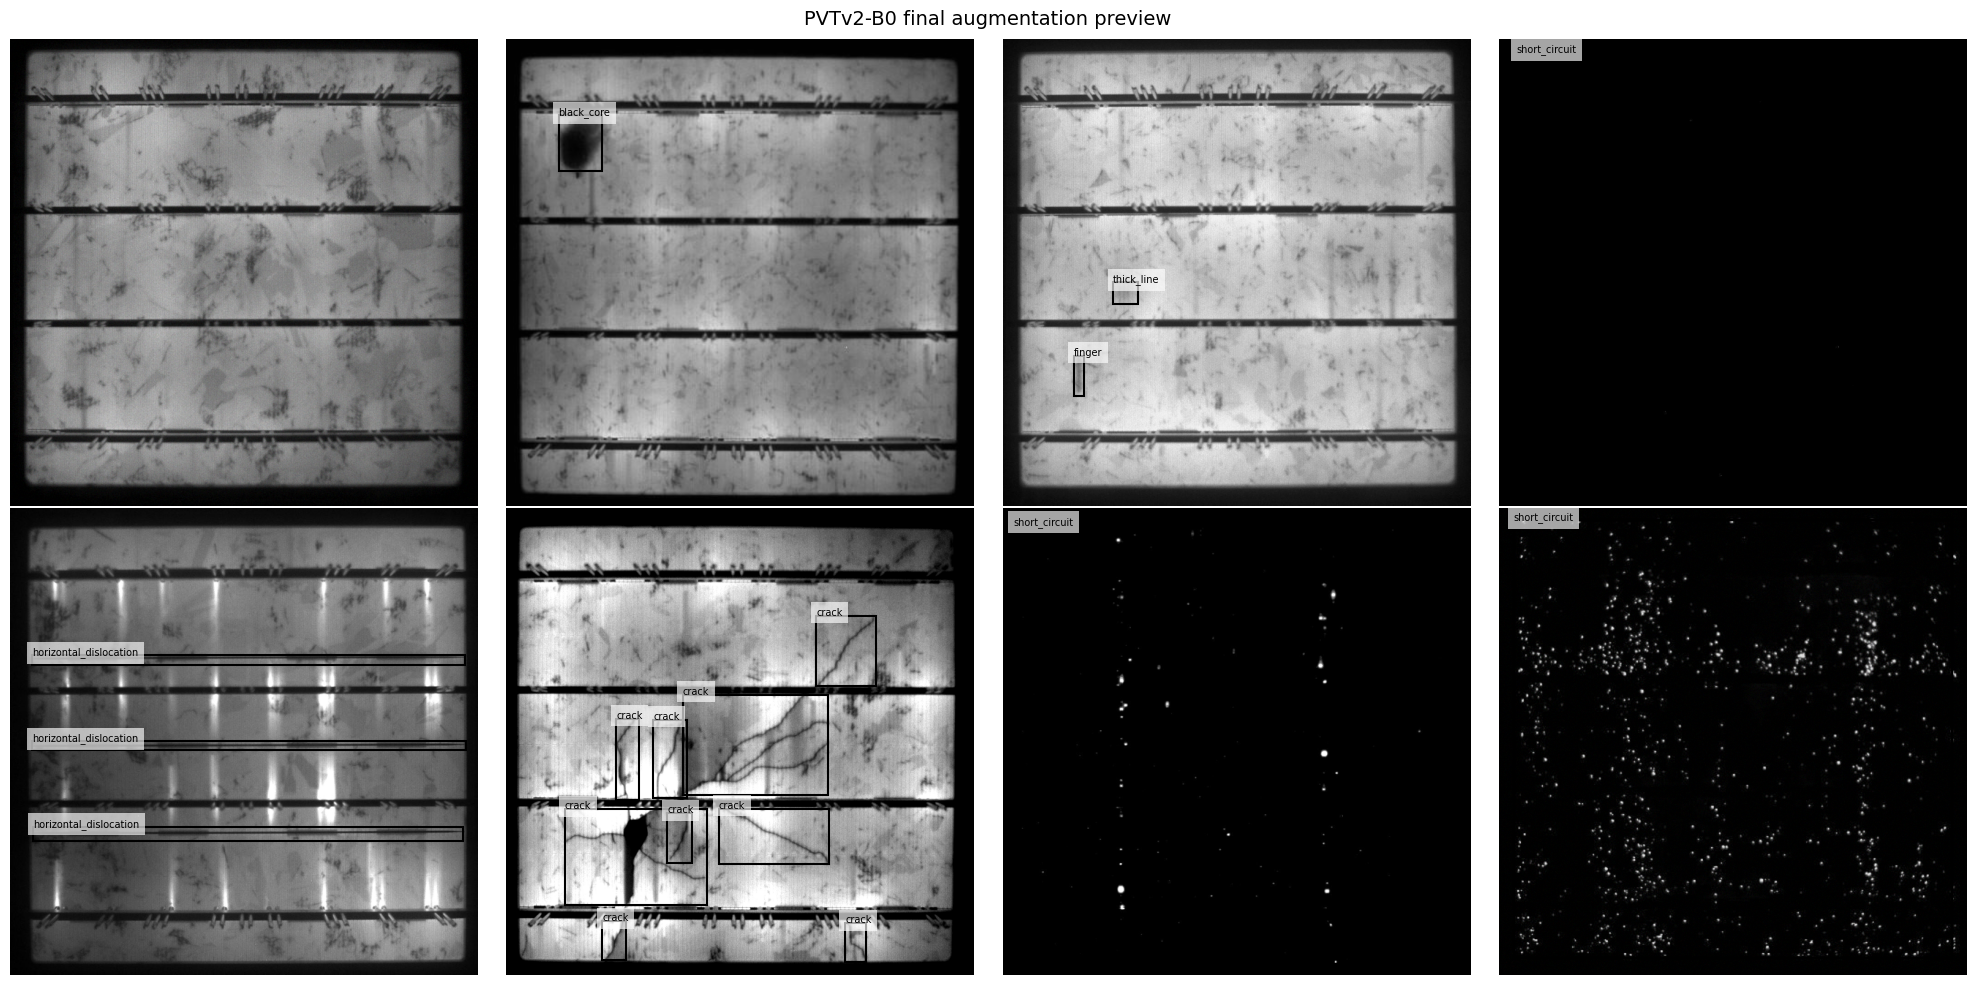

RNGs reset after preflight.


In [11]:
from matplotlib.patches import Rectangle

def augmentation_preflight(
    dataset,
    sample_count=1000,
):
    selector = random.Random(SEED)

    indices = [
        selector.randrange(
            len(dataset)
        )
        for _ in range(sample_count)
    ]

    raw_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64,
    )

    aug_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64,
    )

    invalid = 0

    for idx in indices:
        (
            _,
            raw_boxes,
            raw_labels,
            _,
        ) = dataset._load_raw(idx)

        raw_counts += np.bincount(
            raw_labels,
            minlength=NUM_CLASSES,
        )

        image, target, _ = dataset[idx]

        boxes = (
            target["boxes"]
            .cpu()
            .numpy()
        )

        labels = (
            target["labels"]
            .cpu()
            .numpy()
        )

        aug_counts += np.bincount(
            labels,
            minlength=NUM_CLASSES,
        )

        if len(boxes) != len(raw_boxes):
            invalid += 1
            continue

        if len(boxes):
            if not np.isfinite(
                boxes
            ).all():
                invalid += 1
                continue

            if not (
                (
                    boxes[:, 2]
                    > boxes[:, 0]
                ).all()
                and (
                    boxes[:, 3]
                    > boxes[:, 1]
                ).all()
            ):
                invalid += 1

    print("=" * 70)
    print("AUGMENTATION PREFLIGHT")
    print("=" * 70)
    print(
        "Samples checked:",
        sample_count,
    )
    print(
        "Invalid samples:",
        invalid,
    )

    if invalid != 0:
        raise RuntimeError(
            "Augmentation preflight failed. "
            "Do NOT start training."
        )

    print(
        "\nClass-wise annotation retention:"
    )

    for cls_id, name in enumerate(
        CLASS_NAMES
    ):
        raw_n = int(
            raw_counts[cls_id]
        )

        aug_n = int(
            aug_counts[cls_id]
        )

        if raw_n == 0:
            print(
                f"{name:25s}: "
                "not sampled"
            )
            continue

        print(
            f"{name:25s}: "
            f"{aug_n}/{raw_n} "
            f"({aug_n/raw_n:.1%})"
        )

        if aug_n != raw_n:
            raise RuntimeError(
                f"Annotation count changed "
                f"for {name}. "
                "Do NOT train."
            )

    print(
        "\nPreflight PASSED."
    )


augmentation_preflight(
    train_dataset,
    sample_count=1000,
)


fig, axes = plt.subplots(
    2,
    4,
    figsize=(20, 10),
)

axes = axes.ravel()

preview_rng = random.Random(
    SEED + 1
)

for ax in axes:
    idx = preview_rng.randrange(
        len(train_dataset)
    )

    image, target, _ = (
        train_dataset[idx]
    )

    ax.imshow(
        image
        .permute(1, 2, 0)
        .cpu()
        .numpy()
        .clip(0, 1)
    )

    for box, cls_id in zip(
        target["boxes"].numpy(),
        target["labels"].numpy(),
    ):
        x1, y1, x2, y2 = box

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                linewidth=1.5,
            )
        )

        ax.text(
            x1,
            max(10, y1),
            CLASS_NAMES[
                int(cls_id)
            ],
            fontsize=7,
            bbox=dict(
                facecolor="white",
                alpha=0.65,
                edgecolor="none",
            ),
        )

    ax.axis("off")

plt.suptitle(
    "PVTv2-B0 final augmentation preview",
    fontsize=14,
)

plt.tight_layout()
plt.show()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(
    "RNGs reset after preflight."
)

## 10. Build PVTv2-B0 + deep Mamba + FPN + ASFF + RetinaNet

The already-trained A1 path is preserved:

`PVTv2-B0 → deep bidirectional Mamba → FPN`

Then ASFF is inserted between the FPN and RetinaNet.

### ASFF used here

For each of P3, P4 and P5:
1. P3/P4/P5 are resized to the target level's resolution.
2. Each aligned feature is compressed with a 1×1 convolution.
3. The compressed features predict three spatial weight maps.
4. Softmax normalizes the three weights at every `(x, y)` location.
5. The original 256-channel features are fused by the learned weights.
6. A 3×3 convolution refines the fused feature.
7. A learnable scalar residual gate injects the fused feature into the
   original target FPN level.

P6 and P7 are passed through unchanged.

Each ASFF residual gate starts at `0.0`. Therefore, immediately after
loading the A1 checkpoint, A2 initially follows the exact A1 feature path.

In [12]:
class DeepBidirectionalMamba(
    nn.Module
):
    def __init__(
        self,
        channels,
        d_state=16,
        d_conv=4,
        expand=2,
        gate_init=0.0,
    ):
        super().__init__()

        self.channels = channels

        self.norm = nn.LayerNorm(
            channels
        )

        self.mamba = Mamba(
            d_model=channels,
            d_state=d_state,
            d_conv=d_conv,
            expand=expand,
        )

        self.gate = nn.Parameter(
            torch.tensor(
                float(gate_init)
            )
        )

    def forward(
        self,
        x,
    ):
        # x: [B, C, H, W]
        b, c, h, w = x.shape

        if c != self.channels:
            raise RuntimeError(
                f"Mamba expected {self.channels} channels, "
                f"received {c}."
            )

        seq = (
            x
            .flatten(2)
            .transpose(1, 2)
            .contiguous()
        )

        z = self.norm(
            seq
        )

        y_forward = self.mamba(
            z
        )

        z_reverse = torch.flip(
            z,
            dims=[1],
        )

        y_reverse = self.mamba(
            z_reverse
        )

        y_reverse = torch.flip(
            y_reverse,
            dims=[1],
        )

        y = (
            y_forward
            + y_reverse
        ) * 0.5

        seq = (
            seq
            + torch.tanh(
                self.gate
            ) * y
        )

        out = (
            seq
            .transpose(1, 2)
            .reshape(
                b,
                c,
                h,
                w,
            )
            .contiguous()
        )

        return out


class ASFFFusionLevel(
    nn.Module
):
    def __init__(
        self,
        channels=256,
        compress_channels=8,
        num_levels=3,
        gate_init=0.1,
    ):
        super().__init__()

        self.channels = channels
        self.num_levels = num_levels

        self.compress = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(
                    channels,
                    compress_channels,
                    kernel_size=1,
                    bias=True,
                ),
                nn.ReLU(
                    inplace=True
                ),
            )
            for _ in range(
                num_levels
            )
        ])

        self.weight_logits = nn.Conv2d(
            compress_channels
            * num_levels,
            num_levels,
            kernel_size=1,
            bias=True,
        )

        # Near-uniform softmax weights, but avoid an all-zero
        # kernel so the weighting branch can differentiate levels.
        nn.init.normal_(
            self.weight_logits.weight,
            mean=0.0,
            std=0.01,
        )
        nn.init.zeros_(
            self.weight_logits.bias
        )

        self.refine = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            bias=True,
        )

        # A small non-zero gate lets gradients reach ASFF
        # immediately without overwhelming the transferred A1 path.
        self.gate = nn.Parameter(
            torch.tensor(
                float(gate_init)
            )
        )

    def forward(
        self,
        aligned_features,
        target_index,
    ):
        if len(
            aligned_features
        ) != self.num_levels:
            raise RuntimeError(
                "ASFF received the wrong "
                "number of feature levels."
            )

        compressed = [
            layer(feature)
            for layer, feature
            in zip(
                self.compress,
                aligned_features,
            )
        ]

        logits = self.weight_logits(
            torch.cat(
                compressed,
                dim=1,
            )
        )

        # [B, 3, H, W]
        weights = torch.softmax(
            logits,
            dim=1,
        )

        fused = torch.zeros_like(
            aligned_features[
                target_index
            ]
        )

        for level_idx, feature in enumerate(
            aligned_features
        ):
            fused = (
                fused
                + weights[
                    :,
                    level_idx:
                    level_idx + 1,
                ]
                * feature
            )

        fused = self.refine(
            fused
        )

        base = aligned_features[
            target_index
        ]

        out = (
            base
            + torch.tanh(
                self.gate
            ) * fused
        )

        return out


class AdaptiveSpatialFeatureFusion(
    nn.Module
):
    def __init__(
        self,
        channels=256,
        compress_channels=8,
        num_levels=3,
        gate_init=0.1,
    ):
        super().__init__()

        self.channels = channels
        self.num_levels = num_levels

        self.levels = nn.ModuleList([
            ASFFFusionLevel(
                channels=channels,
                compress_channels=
                    compress_channels,
                num_levels=num_levels,
                gate_init=gate_init,
            )
            for _ in range(
                num_levels
            )
        ])

    @staticmethod
    def _resize_to(
        feature,
        target_hw,
    ):
        current_hw = (
            feature.shape[-2],
            feature.shape[-1],
        )

        if current_hw == target_hw:
            return feature

        # Downsample with adaptive average pooling.
        if (
            current_hw[0]
            >= target_hw[0]
            and current_hw[1]
            >= target_hw[1]
        ):
            return F.adaptive_avg_pool2d(
                feature,
                output_size=target_hw,
            )

        # Upsample with bilinear interpolation.
        return F.interpolate(
            feature,
            size=target_hw,
            mode="bilinear",
            align_corners=False,
        )

    def forward(
        self,
        features,
    ):
        if not isinstance(
            features,
            OrderedDict,
        ):
            features = OrderedDict(
                features
            )

        keys = list(
            features.keys()
        )

        if len(keys) < self.num_levels:
            raise RuntimeError(
                "ASFF requires at least "
                f"{self.num_levels} FPN levels."
            )

        # Main RetinaNet pyramid levels: P3/P4/P5.
        main_keys = keys[
            :self.num_levels
        ]

        main_features = [
            features[key]
            for key in main_keys
        ]

        for feature in main_features:
            if feature.shape[1] != self.channels:
                raise RuntimeError(
                    "ASFF expected "
                    f"{self.channels} channels, "
                    f"received {feature.shape[1]}."
                )

        output = OrderedDict(
            features
        )

        for (
            target_index,
            target_key,
        ) in enumerate(
            main_keys
        ):
            target_hw = (
                main_features[
                    target_index
                ].shape[-2:]
            )

            aligned = [
                self._resize_to(
                    feature,
                    target_hw,
                )
                for feature
                in main_features
            ]

            output[
                target_key
            ] = self.levels[
                target_index
            ](
                aligned,
                target_index,
            )

        # Remaining FPN levels (P6/P7) are unchanged.
        return output


class PVTv2B0MambaASFFFPN(
    nn.Module
):
    def __init__(
        self,
        pretrained=False,
        out_channels=256,
    ):
        super().__init__()

        self.body = timm.create_model(
            "pvt_v2_b0",
            pretrained=pretrained,
            features_only=True,
            out_indices=(1, 2, 3),
        )

        feature_channels = (
            self.body
            .feature_info
            .channels()
        )

        feature_reductions = (
            self.body
            .feature_info
            .reduction()
        )

        print(
            "PVTv2 feature channels:",
            feature_channels,
        )

        print(
            "PVTv2 feature strides :",
            feature_reductions,
        )

        deepest_channels = (
            feature_channels[-1]
        )

        if deepest_channels != 256:
            raise RuntimeError(
                "Expected deepest PVTv2-B0 selected "
                f"feature to have 256 channels, got "
                f"{deepest_channels}."
            )

        self.deep_mamba = (
            DeepBidirectionalMamba(
                channels=deepest_channels,
                d_state=16,
                d_conv=4,
                expand=2,
                # The actual trained A1 gate value is loaded
                # from A1 best.pt.
                gate_init=0.0,
            )
        )

        self.fpn = (
            FeaturePyramidNetwork(
                in_channels_list=
                    feature_channels,

                out_channels=
                    out_channels,

                extra_blocks=
                    LastLevelP6P7(
                        feature_channels[-1],
                        out_channels,
                    ),
            )
        )

        self.asff = (
            AdaptiveSpatialFeatureFusion(
                channels=ASFF_CONFIG[
                    "channels"
                ],
                compress_channels=
                    ASFF_CONFIG[
                        "compress_channels"
                    ],
                num_levels=3,
                gate_init=
                    ASFF_CONFIG[
                        "residual_gate_init"
                    ],
            )
        )

        self.out_channels = (
            out_channels
        )

    def forward(
        self,
        x,
    ):
        features = self.body(
            x
        )

        # Existing A1 Mamba path.
        features[-1] = (
            self.deep_mamba(
                features[-1]
            )
        )

        features = OrderedDict(
            (
                str(i),
                feat,
            )
            for i, feat
            in enumerate(features)
        )

        fpn_features = self.fpn(
            features
        )

        # New A2 module.
        return self.asff(
            fpn_features
        )


def build_model():
    backbone = (
        PVTv2B0MambaASFFFPN(
            pretrained=False,
            out_channels=256,
        )
    )

    model = RetinaNet(
        backbone=backbone,
        num_classes=NUM_CLASSES,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        image_mean=[
            0.485,
            0.456,
            0.406,
        ],
        image_std=[
            0.229,
            0.224,
            0.225,
        ],
        score_thresh=0.001,
        detections_per_img=100,
    )

    return model


model = build_model()


# ------------------------------------------------------------
# Load the trained A1 detector.
# Only the new backbone.asff.* parameters may be missing.
# ------------------------------------------------------------
a1_checkpoint = torch.load(
    A1_BEST_PT,
    map_location="cpu",
)

a1_state = (
    a1_checkpoint[
        "model_state"
    ]
)

load_result = (
    model.load_state_dict(
        a1_state,
        strict=False,
    )
)

missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)

bad_missing = [
    key
    for key in missing_keys
    if not key.startswith(
        "backbone.asff."
    )
]

if bad_missing:
    raise RuntimeError(
        "Unexpected missing non-ASFF weights "
        f"when loading A1: {bad_missing[:10]}"
    )

if unexpected_keys:
    raise RuntimeError(
        "Unexpected A1 checkpoint keys: "
        f"{unexpected_keys[:10]}"
    )

if not missing_keys:
    raise RuntimeError(
        "No new ASFF parameters were detected. "
        "Check the A2 architecture."
    )

print(
    f"Loaded A1 checkpoint from epoch "
    f"{a1_checkpoint.get('epoch', 'unknown')}"
)

print(
    "A1 validation mAP50-95 stored in checkpoint:",
    a1_checkpoint.get(
        "best_map50_95",
        "not stored",
    ),
)

print(
    "New ASFF-only keys:",
    len(missing_keys),
)

print(
    "Unexpected checkpoint keys:",
    len(unexpected_keys),
)

model = model.to(
    DEVICE
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

mamba_params = sum(
    p.numel()
    for p
    in model.backbone.deep_mamba.parameters()
)

asff_params = sum(
    p.numel()
    for p
    in model.backbone.asff.parameters()
)

print(
    f"Total parameters     : "
    f"{total_params:,} "
    f"({total_params/1e6:.3f} M)"
)

print(
    f"Trainable parameters : "
    f"{trainable_params:,} "
    f"({trainable_params/1e6:.3f} M)"
)

print(
    f"Mamba parameters     : "
    f"{mamba_params:,} "
    f"({mamba_params/1e6:.3f} M)"
)

print(
    f"ASFF parameters      : "
    f"{asff_params:,} "
    f"({asff_params/1e6:.3f} M)"
)

print(
    "Loaded A1 Mamba residual gate:",
    float(
        model.backbone
        .deep_mamba
        .gate
        .detach()
        .cpu()
    ),
)

print(
    "Initial A2 ASFF residual gates:",
    [
        float(
            level.gate
            .detach()
            .cpu()
        )
        for level
        in model.backbone
        .asff
        .levels
    ],
)


# ------------------------------------------------------------
# Feature-shape sanity test.
# ------------------------------------------------------------
model.eval()

with torch.no_grad():
    dummy = torch.zeros(
        1,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=DEVICE,
    )

    body_features = (
        model.backbone.body(
            dummy
        )
    )

    body_features[-1] = (
        model.backbone
        .deep_mamba(
            body_features[-1]
        )
    )

    ordered = OrderedDict(
        (
            str(i),
            feat,
        )
        for i, feat
        in enumerate(
            body_features
        )
    )

    raw_fpn = (
        model.backbone
        .fpn(
            ordered
        )
    )

    fused_fpn = (
        model.backbone
        .asff(
            raw_fpn
        )
    )

print(
    "Raw FPN shapes:",
    {
        key: tuple(value.shape)
        for key, value
        in raw_fpn.items()
    },
)

print(
    "ASFF output shapes:",
    {
        key: tuple(value.shape)
        for key, value
        in fused_fpn.items()
    },
)

for key in raw_fpn:
    if (
        raw_fpn[key].shape
        != fused_fpn[key].shape
    ):
        raise RuntimeError(
            f"ASFF changed FPN shape at {key}."
        )

print(
    "✅ FPN/ASFF shape sanity check passed."
)

del dummy
del body_features
del ordered
del raw_fpn
del fused_fpn

gc.collect()
torch.cuda.empty_cache()


PVTv2 feature channels: [64, 160, 256]
PVTv2 feature strides : [8, 16, 32]
Loaded A1 checkpoint from epoch 3
A1 validation mAP50-95 stored in checkpoint: 0.6045351028442383
New ASFF-only keys: 33
Unexpected checkpoint keys: 0
Total parameters     : 13,701,378 (13.701 M)
Trainable parameters : 13,701,378 (13.701 M)
Mamba parameters     : 438,273 (0.438 M)
ASFF parameters      : 1,788,972 (1.789 M)
Loaded A1 Mamba residual gate: -0.00045503315050154924
Initial A2 ASFF residual gates: [0.10000000149011612, 0.10000000149011612, 0.10000000149011612]
Raw FPN shapes: {'0': (1, 256, 80, 80), '1': (1, 256, 40, 40), '2': (1, 256, 20, 20), 'p6': (1, 256, 10, 10), 'p7': (1, 256, 5, 5)}
ASFF output shapes: {'0': (1, 256, 80, 80), '1': (1, 256, 40, 40), '2': (1, 256, 20, 20), 'p6': (1, 256, 10, 10), 'p7': (1, 256, 5, 5)}
✅ FPN/ASFF shape sanity check passed.


## 11. Optimizer, staged differential learning rates and AMP

A2 is initialized from the already-trained A1 checkpoint.

Stage 1 — ASFF-only warm-up (epochs 1–3):
- PVT body: frozen
- FPN + RetinaNet head: frozen
- Mamba: frozen
- ASFF: `2e-4`

Stage 2 — joint fine-tuning (epoch 4 onward):
- existing PVT body: `2e-6`
- existing FPN + RetinaNet head: `1e-5`
- existing Mamba block: `1e-5`
- new ASFF block: `1e-4`

The joint-stage learning rates decay with a cosine schedule down to `1e-6`.
This protects the already-good A1 weights while giving the new ASFF branch time
to learn useful fusion first.


In [13]:
pvt_body_params = list(
    model.backbone
    .body
    .parameters()
)

mamba_params_list = list(
    model.backbone
    .deep_mamba
    .parameters()
)

asff_params_list = list(
    model.backbone
    .asff
    .parameters()
)

fpn_head_params = (
    list(
        model.backbone
        .fpn
        .parameters()
    )
    + list(
        model.head
        .parameters()
    )
)

# Verify parameter groups are disjoint.
all_group_ids = (
    [id(p) for p in pvt_body_params]
    + [id(p) for p in fpn_head_params]
    + [id(p) for p in mamba_params_list]
    + [id(p) for p in asff_params_list]
)

if (
    len(all_group_ids)
    != len(set(all_group_ids))
):
    raise RuntimeError(
        "Optimizer parameter groups overlap."
    )

grouped_ids = set(
    all_group_ids
)

trainable_ids = {
    id(p)
    for p in model.parameters()
    if p.requires_grad
}

missing_from_optimizer = (
    trainable_ids
    - grouped_ids
)

if missing_from_optimizer:
    raise RuntimeError(
        f"{len(missing_from_optimizer)} trainable "
        "parameters were not assigned to the optimizer."
    )

optimizer = torch.optim.AdamW(
    [
        {
            "params":
                pvt_body_params,
            "lr":
                LR_PVT_BODY,
            "name":
                "pvt_body",
        },

        {
            "params":
                fpn_head_params,
            "lr":
                LR_FPN_HEAD,
            "name":
                "fpn_retinanet",
        },

        {
            "params":
                mamba_params_list,
            "lr":
                LR_MAMBA,
            "name":
                "mamba",
        },

        {
            "params":
                asff_params_list,
            "lr":
                LR_ASFF,
            "name":
                "asff",
        },
    ],
    weight_decay=WEIGHT_DECAY,
)


def _set_trainable(
    module,
    enabled,
):
    for parameter in module.parameters():
        parameter.requires_grad = enabled


def configure_training_stage(
    epoch,
):
    """Apply freezing + LR schedule for the current epoch."""

    if epoch <= ASFF_ONLY_EPOCHS:
        stage = "ASFF-only warm-up"

        _set_trainable(
            model.backbone.body,
            False,
        )
        _set_trainable(
            model.backbone.deep_mamba,
            False,
        )
        _set_trainable(
            model.backbone.fpn,
            False,
        )
        _set_trainable(
            model.head,
            False,
        )
        _set_trainable(
            model.backbone.asff,
            True,
        )

        lr_by_name = {
            "pvt_body": 0.0,
            "fpn_retinanet": 0.0,
            "mamba": 0.0,
            "asff": LR_ASFF_WARMUP,
        }

        cosine_factor = 1.0

    else:
        stage = "joint fine-tuning"

        _set_trainable(
            model.backbone.body,
            True,
        )
        _set_trainable(
            model.backbone.deep_mamba,
            True,
        )
        _set_trainable(
            model.backbone.fpn,
            True,
        )
        _set_trainable(
            model.head,
            True,
        )
        _set_trainable(
            model.backbone.asff,
            True,
        )

        joint_total = max(
            1,
            MAX_EPOCHS
            - ASFF_ONLY_EPOCHS,
        )

        joint_index = (
            epoch
            - ASFF_ONLY_EPOCHS
            - 1
        )

        progress = (
            joint_index
            / max(
                1,
                joint_total - 1,
            )
        )

        progress = float(
            np.clip(
                progress,
                0.0,
                1.0,
            )
        )

        cosine_factor = (
            0.5
            * (
                1.0
                + np.cos(
                    np.pi
                    * progress
                )
            )
        )

        lr_by_name = {
            "pvt_body": max(
                MIN_LR,
                LR_PVT_BODY
                * cosine_factor,
            ),
            "fpn_retinanet": max(
                MIN_LR,
                LR_FPN_HEAD
                * cosine_factor,
            ),
            "mamba": max(
                MIN_LR,
                LR_MAMBA
                * cosine_factor,
            ),
            "asff": max(
                MIN_LR,
                LR_ASFF
                * cosine_factor,
            ),
        }

    for group in optimizer.param_groups:
        group["lr"] = lr_by_name[
            group["name"]
        ]

    return {
        "stage": stage,
        "cosine_factor": cosine_factor,
        "lr_by_name": lr_by_name,
    }


def keep_frozen_modules_in_eval(
    stage,
):
    # RetinaNet itself must remain in training mode so it returns
    # losses. Only the frozen transferred modules are put in eval.
    if stage == "ASFF-only warm-up":
        model.backbone.body.eval()
        model.backbone.deep_mamba.eval()
        model.backbone.fpn.eval()
        model.head.eval()
        model.backbone.asff.train()


try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP,
    )
except TypeError:
    scaler = (
        torch.cuda.amp
        .GradScaler(
            enabled=AMP,
        )
    )


def autocast_context():
    try:
        return torch.amp.autocast(
            "cuda",
            enabled=AMP,
        )
    except TypeError:
        return torch.cuda.amp.autocast(
            enabled=AMP,
        )


print(
    "Optimizer: AdamW"
)

print(
    "Stage 1: epochs 1-"
    f"{ASFF_ONLY_EPOCHS} ASFF only, "
    f"LR={LR_ASFF_WARMUP}"
)

print(
    "Stage 2 base LRs:"
)

for group in optimizer.param_groups:
    print(
        group.get(
            "name",
            "unnamed"
        ),
        "LR =",
        group["lr"],
    )

print(
    "AMP:",
    AMP,
)


Optimizer: AdamW
Stage 1: epochs 1-3 ASFF only, LR=0.0002
Stage 2 base LRs:
pvt_body LR = 2e-06
fpn_retinanet LR = 1e-05
mamba LR = 1e-05
asff LR = 0.0001
AMP: True


## 12. Validation helpers

In [14]:
def move_targets_to_device(targets):
    return [
        {
            k: v.to(
                DEVICE,
                non_blocking=True,
            )
            for k, v in t.items()
        }
        for t in targets
    ]


@torch.no_grad()
def compute_validation_loss(model, loader):
    # Torchvision detection models return losses in train mode.
    # PVTv2-B0 in timm has no random augmentation here;
    # gradients remain disabled by @torch.no_grad().
    model.train()

    total_cls = 0.0
    total_box = 0.0
    total_images = 0

    start = time.perf_counter()

    for images, targets, _ in loader:
        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(targets)

        with autocast_context():
            losses = model(
                images,
                targets,
            )

        batch_n = len(images)

        total_cls += (
            float(
                losses["classification"].detach()
            )
            * batch_n
        )

        total_box += (
            float(
                losses["bbox_regression"].detach()
            )
            * batch_n
        )

        total_images += batch_n

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    model.eval()

    cls_loss = (
        total_cls
        / max(total_images, 1)
    )

    box_loss = (
        total_box
        / max(total_images, 1)
    )

    return {
        "classification_loss": cls_loss,
        "bbox_regression_loss": box_loss,
        "total_loss": cls_loss + box_loss,
        "seconds": seconds,
    }


@torch.no_grad()
def evaluate_map(model, loader):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=False,
    )

    start = time.perf_counter()

    for images, targets, _ in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        with autocast_context():
            outputs = model(images_gpu)

        preds = [
            {
                "boxes": out["boxes"].detach().cpu(),
                "scores": out["scores"].detach().cpu(),
                "labels": out["labels"].detach().cpu(),
            }
            for out in outputs
        ]

        gts = [
            {
                "boxes": t["boxes"].detach().cpu(),
                "labels": t["labels"].detach().cpu(),
            }
            for t in targets
        ]

        metric.update(preds, gts)

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    result = metric.compute()

    return {
        "map50": float(result["map_50"]),
        "map75": float(result["map_75"]),
        "map50_95": float(result["map"]),
        "seconds": seconds,
    }

# Fresh A2 start or resume

## 13. Resume support

For a brand-new A2 run:

```python
RESUME = False
```

If Colab disconnects after at least one completed A2 epoch:
1. reconnect to GPU,
2. rerun setup/model/optimizer cells,
3. set `RESUME = True`,
4. rerun this cell and the training cell.

`last.pt` belongs only to this A2 Mamba + ASFF experiment.

In [15]:
history = []
start_epoch = 1

best_map = -1.0
best_epoch = 0
epochs_without_improvement = 0

if RESUME:
    if not LAST_PT.exists():
        raise FileNotFoundError(
            f"No resume checkpoint found: {LAST_PT}"
        )

    checkpoint = torch.load(
        LAST_PT,
        map_location=DEVICE,
    )

    model.load_state_dict(
        checkpoint["model_state"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state"]
    )

    if "scaler_state" in checkpoint:
        scaler.load_state_dict(
            checkpoint["scaler_state"]
        )

    start_epoch = (
        int(checkpoint["epoch"])
        + 1
    )

    best_map = float(
        checkpoint["best_map"]
    )

    best_epoch = int(
        checkpoint["best_epoch"]
    )

    epochs_without_improvement = int(
        checkpoint[
            "epochs_without_improvement"
        ]
    )

    history = checkpoint.get(
        "history",
        [],
    )

    print(
        f"Resuming from epoch "
        f"{start_epoch}"
    )

else:
    if LAST_PT.exists():
        raise RuntimeError(
            "Existing last.pt found after fresh-run archiving. "
            "Check the output folder before continuing."
        )

    print(
        "Starting a fresh A2 "
        "PVTv2-B0 + Mamba + ASFF + RetinaNet Aug run."
    )


Starting a fresh A2 PVTv2-B0 + Mamba + ASFF + RetinaNet Aug run.


### 12.1 A1-transfer sanity check and epoch-0 fallback

For a fresh run only, the notebook temporarily sets the three ASFF residual
gates to zero and evaluates the exact transferred A1 path on validation data.

That validation result becomes the epoch-0 baseline and is saved immediately as
`best.pt`. Therefore a trained ASFF checkpoint replaces it only if validation
mAP@50–95 actually improves over the transferred A1 detector.

After saving the baseline, the ASFF gates are restored to the revised training
initialization of `0.1`, so gradients can immediately reach the fusion branch.

This check uses validation data only — never the test set.


In [16]:
if not RESUME:
    print(
        "Checking exact transferred A1 path on validation set..."
    )

    training_gate_init = float(
        ASFF_CONFIG[
            "residual_gate_init"
        ]
    )

    # Temporarily disable the new ASFF residual contribution so
    # this validation pass is exactly the transferred A1 path.
    with torch.no_grad():
        for level in (
            model.backbone
            .asff
            .levels
        ):
            level.gate.zero_()

    initial_val = evaluate_map(
        model,
        val_loader,
    )

    initial_asff_gates = [
        float(
            level.gate
            .detach()
            .cpu()
        )
        for level
        in model.backbone
        .asff
        .levels
    ]

    # Epoch 0 becomes the protected A1 fallback.
    best_map = float(
        initial_val[
            "map50_95"
        ]
    )
    best_epoch = 0
    epochs_without_improvement = 0

    best_state = {
        "epoch": 0,
        "best_map50_95": best_map,

        "model_state": {
            k: v.detach().cpu()
            for k, v
            in model.state_dict().items()
        },

        "class_names": CLASS_NAMES,
        "training_config":
            training_config,
    }

    torch.save(
        best_state,
        BEST_PT,
    )

    # Restore the revised non-zero ASFF gates for actual training.
    with torch.no_grad():
        for level in (
            model.backbone
            .asff
            .levels
        ):
            level.gate.fill_(
                training_gate_init
            )

    training_start_asff_gates = [
        float(
            level.gate
            .detach()
            .cpu()
        )
        for level
        in model.backbone
        .asff
        .levels
    ]

    initial_val_df = pd.DataFrame([
        {
            "source_A1_checkpoint":
                str(A1_BEST_PT),

            "stored_A1_val_mAP50-95":
                a1_checkpoint.get(
                    "best_map50_95",
                    np.nan,
                ),

            "A2_initial_val_mAP50":
                initial_val[
                    "map50"
                ],

            "A2_initial_val_mAP75":
                initial_val[
                    "map75"
                ],

            "A2_initial_val_mAP50-95":
                initial_val[
                    "map50_95"
                ],

            "initial_ASFF_gate_P3":
                initial_asff_gates[0],

            "initial_ASFF_gate_P4":
                initial_asff_gates[1],

            "initial_ASFF_gate_P5":
                initial_asff_gates[2],

            "training_start_ASFF_gate_P3":
                training_start_asff_gates[0],

            "training_start_ASFF_gate_P4":
                training_start_asff_gates[1],

            "training_start_ASFF_gate_P5":
                training_start_asff_gates[2],
        }
    ])

    initial_val_df.to_csv(
        METRICS_DIR
        / "initial_transfer_validation.csv",
        index=False,
    )

    display(
        initial_val_df
    )

    stored_a1 = (
        a1_checkpoint.get(
            "best_map50_95"
        )
    )

    if stored_a1 is not None:
        difference = abs(
            initial_val[
                "map50_95"
            ]
            - float(stored_a1)
        )

        print(
            "Absolute difference from stored "
            f"A1 val mAP50-95: {difference:.6f}"
        )

        if difference > 0.002:
            warnings.warn(
                "Exact transferred A1 validation metric differs "
                "from the stored A1 metric by >0.002. "
                "Check transfer/loading before training."
            )

    print(
        "Epoch-0 fallback saved with val mAP50-95:",
        round(best_map, 6),
    )

    print(
        "ASFF gates restored for training:",
        training_start_asff_gates,
    )

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    print(
        "RNGs reset after transfer sanity check."
    )
else:
    print(
        "Resume mode: initial A1-transfer check skipped."
    )


Checking exact transferred A1 path on validation set...


,source_A1_checkpoint,stored_A1_val_mAP50-95,A2_initial_val_mAP50,A2_initial_val_mAP75,A2_initial_val_mAP50-95,initial_ASFF_gate_P3,initial_ASFF_gate_P4,initial_ASFF_gate_P5,training_start_ASFF_gate_P3,training_start_ASFF_gate_P4,training_start_ASFF_gate_P5
0,/content/drive/MyDrive/Study Materials /CSE465...,0.604535,0.934239,0.600073,0.604535,0.0,0.0,0.0,0.1,0.1,0.1


Absolute difference from stored A1 val mAP50-95: 0.000000
Epoch-0 fallback saved with val mAP50-95: 0.604535
ASFF gates restored for training: [0.10000000149011612, 0.10000000149011612, 0.10000000149011612]
RNGs reset after transfer sanity check.


## 13. Train — live epoch/batch progress

The model is selected using validation **mAP@50–95**.

Training schedule:
- epochs 1–3: ASFF-only warm-up
- epoch 4 onward: joint fine-tuning with conservative A1 learning rates
- maximum = 25 epochs
- early-stopping patience = 7 joint fine-tuning epochs

Warm-up epochs do not consume early-stopping patience.
The live progress bar shows current batch loss and VRAM.
The training history also stores the three learned ASFF residual gates and the
active training stage.


In [17]:
from tqdm.auto import tqdm

for epoch in range(
    start_epoch,
    MAX_EPOCHS + 1,
):

    stage_info = configure_training_stage(
        epoch
    )

    model.train()

    keep_frozen_modules_in_eval(
        stage_info["stage"]
    )

    print(
        f"\nTraining stage: {stage_info['stage']}"
    )

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    epoch_start = time.perf_counter()

    train_cls_sum = 0.0
    train_box_sum = 0.0
    train_images = 0

    optimizer.zero_grad(
        set_to_none=True
    )

    n_steps = len(train_loader)

    train_bar = tqdm(
        enumerate(train_loader),
        total=n_steps,
        desc=f"Epoch {epoch}/{MAX_EPOCHS}",
        dynamic_ncols=True,
    )

    for step, (
        images,
        targets,
        _,
    ) in train_bar:

        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(
            targets
        )

        group_start = (
            step // ACCUM_STEPS
        ) * ACCUM_STEPS

        group_end = min(
            group_start + ACCUM_STEPS,
            n_steps,
        )

        group_size = (
            group_end - group_start
        )

        with autocast_context():
            losses = model(
                images,
                targets,
            )

            cls_loss = losses[
                "classification"
            ]

            box_loss = losses[
                "bbox_regression"
            ]

            total_loss = (
                cls_loss + box_loss
            )

            if not torch.isfinite(
                total_loss
            ):
                raise RuntimeError(
                    f"Non-finite training loss at "
                    f"epoch {epoch}, step {step}. "
                    "Training stopped immediately."
                )

            scaled_loss = (
                total_loss
                / group_size
            )

        scaler.scale(
            scaled_loss
        ).backward()

        if step == group_end - 1:
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP,
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

        batch_n = len(images)

        train_cls_sum += (
            float(cls_loss.detach())
            * batch_n
        )

        train_box_sum += (
            float(box_loss.detach())
            * batch_n
        )

        train_images += batch_n

        train_bar.set_postfix({
            "loss": (
                f"{float(total_loss.detach()):.4f}"
            ),
            "cls": (
                f"{float(cls_loss.detach()):.4f}"
            ),
            "box": (
                f"{float(box_loss.detach()):.4f}"
            ),
            "VRAM": (
                f"{torch.cuda.memory_allocated()/1024**3:.1f}G"
            ),
        })

    torch.cuda.synchronize()

    train_seconds = (
        time.perf_counter()
        - epoch_start
    )

    train_cls = (
        train_cls_sum
        / train_images
    )

    train_box = (
        train_box_sum
        / train_images
    )

    train_total = (
        train_cls + train_box
    )

    print(
        "\nCalculating validation loss..."
    )

    val_loss_result = (
        compute_validation_loss(
            model,
            val_loader,
        )
    )

    print(
        "Calculating validation mAP..."
    )

    val_map_result = evaluate_map(
        model,
        val_loader,
    )

    total_seconds = (
        train_seconds
        + val_loss_result["seconds"]
        + val_map_result["seconds"]
    )

    peak_vram_gb = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    record = {
        "epoch": epoch,

        "training_stage":
            stage_info["stage"],

        "train/classification_loss":
            train_cls,

        "train/bbox_regression_loss":
            train_box,

        "train/total_loss":
            train_total,

        "val/classification_loss":
            val_loss_result[
                "classification_loss"
            ],

        "val/bbox_regression_loss":
            val_loss_result[
                "bbox_regression_loss"
            ],

        "val/total_loss":
            val_loss_result[
                "total_loss"
            ],

        "val/mAP50":
            val_map_result["map50"],

        "val/mAP75":
            val_map_result["map75"],

        "val/mAP50-95":
            val_map_result["map50_95"],

        "train_seconds":
            train_seconds,

        "val_loss_seconds":
            val_loss_result["seconds"],

        "val_map_seconds":
            val_map_result["seconds"],

        "total_seconds":
            total_seconds,

        "lr":
            optimizer.param_groups[0]["lr"],

        "lr_pvt_body":
            optimizer.param_groups[0]["lr"],

        "lr_fpn_head":
            optimizer.param_groups[1]["lr"],

        "lr_mamba":
            optimizer.param_groups[2]["lr"],

        "lr_asff":
            optimizer.param_groups[3]["lr"],

        "mamba_gate":
            float(
                model.backbone
                .deep_mamba
                .gate
                .detach()
                .cpu()
            ),

        "asff_gate_P3":
            float(
                model.backbone
                .asff
                .levels[0]
                .gate
                .detach()
                .cpu()
            ),

        "asff_gate_P4":
            float(
                model.backbone
                .asff
                .levels[1]
                .gate
                .detach()
                .cpu()
            ),

        "asff_gate_P5":
            float(
                model.backbone
                .asff
                .levels[2]
                .gate
                .detach()
                .cpu()
            ),

        "peak_vram_GB":
            peak_vram_gb,
    }

    history.append(record)

    history_df = pd.DataFrame(
        history
    )

    history_df.to_csv(
        METRICS_DIR
        / "training_history.csv",
        index=False,
    )

    current_map = (
        val_map_result["map50_95"]
    )

    if (
        not np.isfinite(current_map)
        or current_map < 0
    ):
        raise RuntimeError(
            f"Invalid validation mAP50-95 "
            f"at epoch {epoch}: {current_map}. "
            "Checkpoint remains available from the "
            "previous completed epoch."
        )

    improved = (
        current_map > best_map
    )

    if improved:
        best_map = current_map
        best_epoch = epoch

        epochs_without_improvement = 0

        best_state = {
            "epoch": epoch,
            "best_map50_95": best_map,

            "model_state": {
                k: v.detach().cpu()
                for k, v
                in model.state_dict().items()
            },

            "class_names": CLASS_NAMES,
            "training_config":
                training_config,
        }

        torch.save(
            best_state,
            BEST_PT,
        )

    else:
        # Warm-up epochs do not consume early-stopping patience.
        if epoch > ASFF_ONLY_EPOCHS:
            epochs_without_improvement += 1
        else:
            epochs_without_improvement = 0

    last_state = {
        "epoch": epoch,

        "model_state":
            model.state_dict(),

        "optimizer_state":
            optimizer.state_dict(),

        "training_stage":
            stage_info["stage"],

        "scaler_state":
            scaler.state_dict(),

        "best_map":
            best_map,

        "best_epoch":
            best_epoch,

        "epochs_without_improvement":
            epochs_without_improvement,

        "history":
            history,

        "training_config":
            training_config,
    }

    torch.save(
        last_state,
        LAST_PT,
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"EPOCH {epoch}/{MAX_EPOCHS} COMPLETE"
    )

    print(
        f"Stage         : {stage_info['stage']}"
    )

    print("-" * 70)

    print(
        f"Train Loss    : "
        f"{train_total:.4f} "
        f"(Cls {train_cls:.4f} | "
        f"Box {train_box:.4f})"
    )

    print(
        f"Val Loss      : "
        f"{val_loss_result['total_loss']:.4f}"
    )

    print(
        f"Val mAP@50    : "
        f"{val_map_result['map50']:.4f}"
    )

    print(
        f"Val mAP@75    : "
        f"{val_map_result['map75']:.4f}"
    )

    print(
        f"Val mAP@50-95 : "
        f"{current_map:.4f}"
    )

    print("-" * 70)

    print(
        f"Train time    : "
        f"{train_seconds/60:.2f} min"
    )

    print(
        f"Val-loss time : "
        f"{val_loss_result['seconds']/60:.2f} min"
    )

    print(
        f"Val-mAP time  : "
        f"{val_map_result['seconds']/60:.2f} min"
    )

    print(
        f"Total epoch   : "
        f"{total_seconds/60:.2f} min"
    )

    print(
        f"Peak VRAM     : "
        f"{peak_vram_gb:.2f} GB"
    )

    print("-" * 70)

    print(
        f"Best epoch    : "
        f"{best_epoch}"
    )

    print(
        f"Best mAP50-95 : "
        f"{best_map:.4f}"
    )

    print(
        f"Early stopping: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    current_asff_gates = [
        float(
            level.gate
            .detach()
            .cpu()
        )
        for level
        in model.backbone
        .asff
        .levels
    ]

    print(
        "ASFF gates     : "
        + ", ".join(
            f"{value:.4f}"
            for value
            in current_asff_gates
        )
    )

    print("=" * 70)

    if (
        epoch > ASFF_ONLY_EPOCHS
        and epochs_without_improvement
        >= PATIENCE
    ):
        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch}."
        )

        break

print("\nTRAINING FINISHED")
print("Best epoch:", best_epoch)

print(
    "Best validation mAP@50-95:",
    round(best_map, 4),
)



Training stage: ASFF-only warm-up


Epoch 1/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 1/25 COMPLETE
Stage         : ASFF-only warm-up
----------------------------------------------------------------------
Train Loss    : 0.1829 (Cls 0.0814 | Box 0.1015)
Val Loss      : 0.4935
Val mAP@50    : 0.9253
Val mAP@75    : 0.5734
Val mAP@50-95 : 0.5935
----------------------------------------------------------------------
Train time    : 2.75 min
Val-loss time : 0.34 min
Val-mAP time  : 0.42 min
Total epoch   : 3.52 min
Peak VRAM     : 0.95 GB
----------------------------------------------------------------------
Best epoch    : 0
Best mAP50-95 : 0.6045
Early stopping: 0/5
ASFF gates     : 0.1061, 0.0986, 0.1070

Training stage: ASFF-only warm-up


Epoch 2/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 2/25 COMPLETE
Stage         : ASFF-only warm-up
----------------------------------------------------------------------
Train Loss    : 0.1776 (Cls 0.0787 | Box 0.0989)
Val Loss      : 0.4945
Val mAP@50    : 0.9283
Val mAP@75    : 0.6068
Val mAP@50-95 : 0.6037
----------------------------------------------------------------------
Train time    : 2.74 min
Val-loss time : 0.34 min
Val-mAP time  : 0.43 min
Total epoch   : 3.50 min
Peak VRAM     : 0.96 GB
----------------------------------------------------------------------
Best epoch    : 0
Best mAP50-95 : 0.6045
Early stopping: 0/5
ASFF gates     : 0.1061, 0.0970, 0.1104

Training stage: ASFF-only warm-up


...


Calculating validation loss...
Calculating validation mAP...

EPOCH 12/25 COMPLETE
Stage         : joint fine-tuning
----------------------------------------------------------------------
Train Loss    : 0.1635 (Cls 0.0726 | Box 0.0909)
Val Loss      : 0.5840
Val mAP@50    : 0.9378
Val mAP@75    : 0.6555
Val mAP@50-95 : 0.6235
----------------------------------------------------------------------
Train time    : 3.71 min
Val-loss time : 0.34 min
Val-mAP time  : 0.42 min
Total epoch   : 4.47 min
Peak VRAM     : 2.82 GB
----------------------------------------------------------------------
Best epoch    : 9
Best mAP50-95 : 0.6250
Early stopping: 3/5
ASFF gates     : 0.1001, 0.0890, 0.1068

Training stage: joint fine-tuning


Epoch 13/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 13/25 COMPLETE
Stage         : joint fine-tuning
----------------------------------------------------------------------
Train Loss    : 0.1626 (Cls 0.0730 | Box 0.0896)
Val Loss      : 0.4888
Val mAP@50    : 0.9372
Val mAP@75    : 0.6313
Val mAP@50-95 : 0.6205
----------------------------------------------------------------------
Train time    : 3.70 min
Val-loss time : 0.34 min
Val-mAP time  : 0.41 min
Total epoch   : 4.45 min
Peak VRAM     : 2.81 GB
----------------------------------------------------------------------
Best epoch    : 9
Best mAP50-95 : 0.6250
Early stopping: 4/5
ASFF gates     : 0.0998, 0.0893, 0.1070

Training stage: joint fine-tuning


Epoch 14/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 14/25 COMPLETE
Stage         : joint fine-tuning
----------------------------------------------------------------------
Train Loss    : 0.1599 (Cls 0.0710 | Box 0.0889)
Val Loss      : 0.6742
Val mAP@50    : 0.9375
Val mAP@75    : 0.6444
Val mAP@50-95 : 0.6187
----------------------------------------------------------------------
Train time    : 3.69 min
Val-loss time : 0.35 min
Val-mAP time  : 0.41 min
Total epoch   : 4.46 min
Peak VRAM     : 2.82 GB
----------------------------------------------------------------------
Best epoch    : 9
Best mAP50-95 : 0.6250
Early stopping: 5/5
ASFF gates     : 0.0996, 0.0896, 0.1078

Early stopping triggered at epoch 14.

TRAINING FINISHED
Best epoch: 9
Best validation mAP@50-95: 0.625


# Result

## 14. Training history and timing summary

In [18]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df["epoch"].max()
)

best_checkpoint_meta = torch.load(
    BEST_PT,
    map_location="cpu",
)

best_epoch = int(
    best_checkpoint_meta.get(
        "epoch",
        history_df.loc[
            history_df[
                "val/mAP50-95"
            ].idxmax(),
            "epoch",
        ],
    )
)

best_map_saved = float(
    best_checkpoint_meta.get(
        "best_map50_95",
        history_df[
            "val/mAP50-95"
        ].max(),
    )
)

timing_summary = pd.DataFrame([{
    "epochs_completed":
        epochs_completed,

    "best_epoch":
        best_epoch,

    "best_val_mAP50-95":
        best_map_saved,

    "mean_train_min_per_epoch":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "mean_val_loss_min_per_epoch":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "mean_val_map_min_per_epoch":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "mean_total_min_per_epoch":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "total_training_run_min":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "mean_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].mean(),

    "max_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].max(),
}]).round(4)

timing_summary.to_csv(
    METRICS_DIR
    / "timing_summary.csv",
    index=False,
)

display(timing_summary)


,epochs_completed,best_epoch,best_val_mAP50-95,mean_train_min_per_epoch,mean_val_loss_min_per_epoch,mean_val_map_min_per_epoch,mean_total_min_per_epoch,total_training_run_min,mean_peak_vram_GB,max_peak_vram_GB
0,14,9,0.625,3.4996,0.3458,0.4173,4.2627,59.6782,2.4166,2.8171


## 15. Training vs validation loss curves

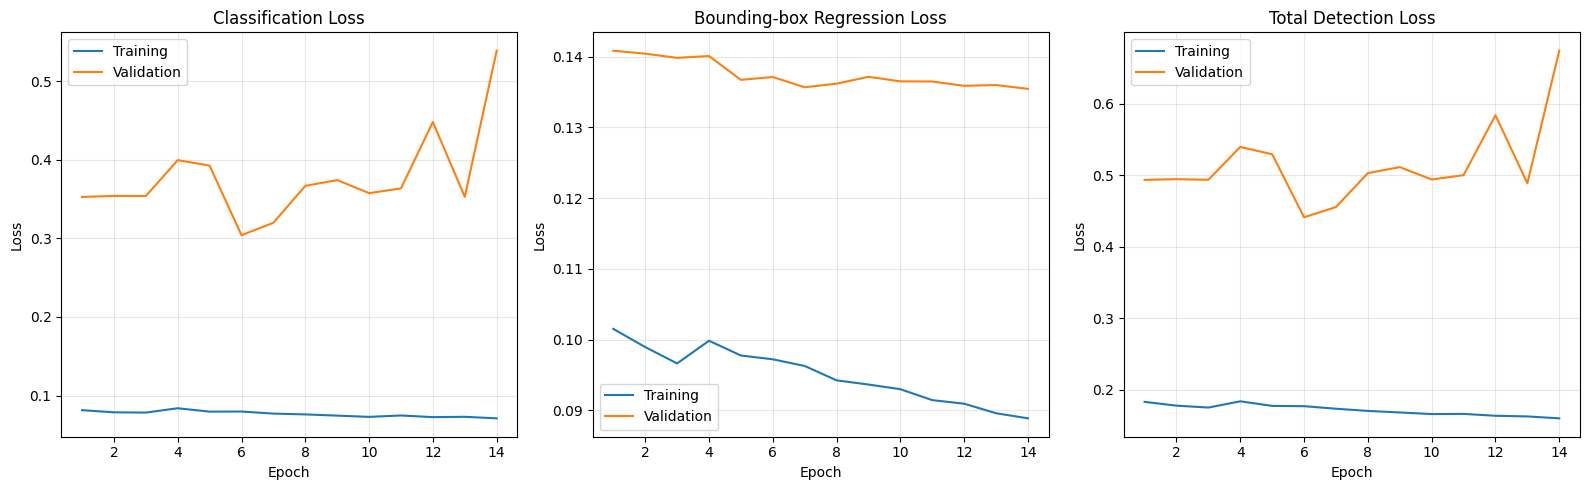

In [19]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

loss_pairs = [
    (
        "train/classification_loss",
        "val/classification_loss",
        "Classification Loss",
    ),
    (
        "train/bbox_regression_loss",
        "val/bbox_regression_loss",
        "Bounding-box Regression Loss",
    ),
    (
        "train/total_loss",
        "val/total_loss",
        "Total Detection Loss",
    ),
]

for ax, (
    train_col,
    val_col,
    title,
) in zip(
    axes,
    loss_pairs,
):
    ax.plot(
        history_df["epoch"],
        history_df[train_col],
        label="Training",
    )

    ax.plot(
        history_df["epoch"],
        history_df[val_col],
        label="Validation",
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "training_validation_loss_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 16. Validation mAP vs epoch

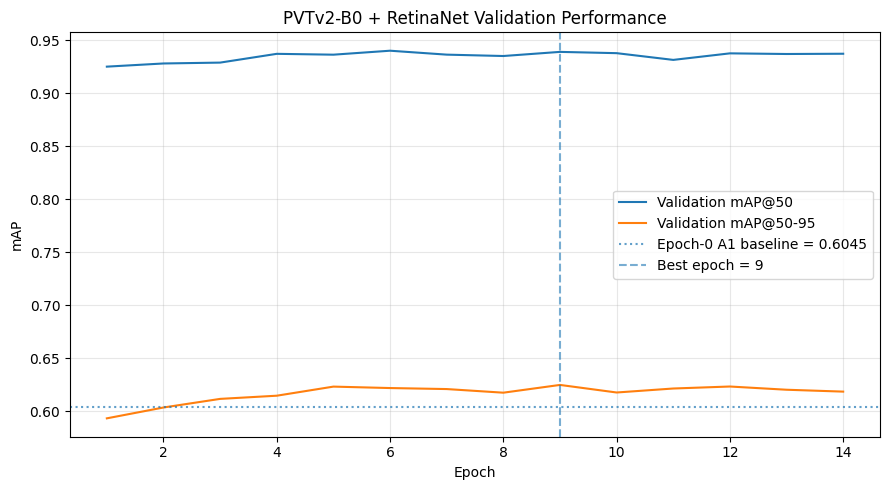

In [20]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50"],
    label="Validation mAP@50",
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50-95"],
    label="Validation mAP@50-95",
)

if (
    METRICS_DIR
    / "initial_transfer_validation.csv"
).exists():
    baseline_df = pd.read_csv(
        METRICS_DIR
        / "initial_transfer_validation.csv"
    )
    baseline_map = float(
        baseline_df.iloc[0][
            "A2_initial_val_mAP50-95"
        ]
    )
    plt.axhline(
        baseline_map,
        linestyle=":",
        alpha=0.7,
        label=(
            "Epoch-0 A1 baseline = "
            f"{baseline_map:.4f}"
        ),
    )

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best epoch = {best_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("mAP")

plt.title(
    "PVTv2-B0 + RetinaNet "
    "Validation Performance"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "validation_map_vs_epoch.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


## 17. Load the best model for final test evaluation

In [21]:
best_checkpoint = torch.load(
    BEST_PT,
    map_location="cpu",
)

model.load_state_dict(
    best_checkpoint["model_state"]
)

model = model.to(DEVICE)
model.eval()

gc.collect()
torch.cuda.empty_cache()

print(
    f"Loaded best model from epoch "
    f"{best_checkpoint['epoch']} "
    f"(val mAP50-95="
    f"{best_checkpoint['best_map50_95']:.4f})"
)

Loaded best model from epoch 9 (val mAP50-95=0.6250)


## 18. Collect test predictions once

In [22]:
@torch.no_grad()
def collect_predictions(
    model,
    loader,
):
    model.eval()

    predictions = []
    targets_all = []
    paths_all = []

    total_forward_seconds = 0.0
    total_images = 0

    for images, targets, paths in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        torch.cuda.synchronize()
        start = time.perf_counter()

        with autocast_context():
            outputs = model(
                images_gpu
            )

        torch.cuda.synchronize()

        total_forward_seconds += (
            time.perf_counter()
            - start
        )

        total_images += len(images)

        for out in outputs:
            predictions.append({
                "boxes":
                    out["boxes"].detach().cpu(),

                "scores":
                    out["scores"].detach().cpu(),

                "labels":
                    out["labels"].detach().cpu(),
            })

        for target in targets:
            targets_all.append({
                "boxes":
                    target["boxes"].detach().cpu(),

                "labels":
                    target["labels"].detach().cpu(),
            })

        paths_all.extend(paths)

    inference_ms = (
        total_forward_seconds
        / max(total_images, 1)
        * 1000
    )

    return (
        predictions,
        targets_all,
        paths_all,
        inference_ms,
    )


(
    test_predictions,
    test_targets,
    test_paths,
    inference_ms,
) = collect_predictions(
    model,
    test_loader,
)

fps = (
    1000 / inference_ms
    if inference_ms > 0
    else np.nan
)

print(
    "Test images:",
    len(test_predictions),
)

print(
    f"Model forward time: "
    f"{inference_ms:.3f} ms/image"
)

print(
    f"FPS: {fps:.2f}"
)

Test images: 949
Model forward time: 28.396 ms/image
FPS: 35.22


## 19. Test mAP50, mAP75 and mAP50–95

In [23]:
map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

map50_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.50],
    class_metrics=True,
)

map_metric.update(
    test_predictions,
    test_targets,
)

map50_metric.update(
    test_predictions,
    test_targets,
)

map_result = (
    map_metric.compute()
)

map50_result = (
    map50_metric.compute()
)

test_map50 = float(
    map_result["map_50"]
)

test_map75 = float(
    map_result["map_75"]
)

test_map50_95 = float(
    map_result["map"]
)

print(
    f"mAP@50    : "
    f"{test_map50:.4f}"
)

print(
    f"mAP@75    : "
    f"{test_map75:.4f}"
)

print(
    f"mAP@50-95 : "
    f"{test_map50_95:.4f}"
)

mAP@50    : 0.9073
mAP@75    : 0.6142
mAP@50-95 : 0.6046


## 20. Precision, Recall, F1, matched box IoU and Dice

Threshold metrics:
- confidence ≥ 0.25
- class-aware one-to-one matching
- TP IoU threshold = 0.50

IoU and Dice are **bounding-box overlap metrics**, not segmentation-mask metrics.

In [24]:
def class_aware_matches(
    pred,
    gt,
    conf_threshold=0.25,
    iou_threshold=0.50,
):
    keep = (
        pred["scores"]
        >= conf_threshold
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    if (
        len(p_boxes) == 0
        or len(g_boxes) == 0
    ):
        return (
            [],
            p_boxes,
            p_labels,
        )

    ious = box_iou(
        p_boxes,
        g_boxes,
    )

    candidates = []

    for pi in range(
        len(p_boxes)
    ):
        for gi in range(
            len(g_boxes)
        ):
            if (
                int(p_labels[pi])
                != int(g_labels[gi])
            ):
                continue

            iou = float(
                ious[pi, gi]
            )

            if (
                iou
                >= iou_threshold
            ):
                candidates.append(
                    (
                        iou,
                        pi,
                        gi,
                    )
                )

    candidates.sort(
        reverse=True
    )

    used_pred = set()
    used_gt = set()
    matches = []

    for iou, pi, gi in candidates:
        if (
            pi in used_pred
            or gi in used_gt
        ):
            continue

        used_pred.add(pi)
        used_gt.add(gi)

        matches.append(
            (
                pi,
                gi,
                iou,
            )
        )

    return (
        matches,
        p_boxes,
        p_labels,
    )


overall_tp = 0
overall_fp = 0
overall_fn = 0

matched_ious = []

per_class_counts = defaultdict(
    lambda: {
        "tp": 0,
        "fp": 0,
        "fn": 0,
        "ious": [],
    }
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    (
        matches,
        p_boxes,
        p_labels,
    ) = class_aware_matches(
        pred,
        gt,
        CONF_THRESHOLD,
        MATCH_IOU_THRESHOLD,
    )

    matched_p = {
        m[0]
        for m in matches
    }

    matched_g = {
        m[1]
        for m in matches
    }

    tp = len(matches)
    fp = len(p_boxes) - tp
    fn = len(gt["boxes"]) - tp

    overall_tp += tp
    overall_fp += fp
    overall_fn += fn

    for (
        pi,
        gi,
        iou,
    ) in matches:
        cls_id = int(
            gt["labels"][gi]
        )

        matched_ious.append(
            iou
        )

        per_class_counts[
            cls_id
        ]["tp"] += 1

        per_class_counts[
            cls_id
        ]["ious"].append(
            iou
        )

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in matched_p:
            per_class_counts[
                int(cls_id)
            ]["fp"] += 1

    for gi, cls_id in enumerate(
        gt["labels"].tolist()
    ):
        if gi not in matched_g:
            per_class_counts[
                int(cls_id)
            ]["fn"] += 1


test_precision = (
    overall_tp
    / (overall_tp + overall_fp)
    if (
        overall_tp + overall_fp
    )
    else 0.0
)

test_recall = (
    overall_tp
    / (overall_tp + overall_fn)
    if (
        overall_tp + overall_fn
    )
    else 0.0
)

test_f1 = (
    2
    * test_precision
    * test_recall
    / (
        test_precision
        + test_recall
    )
    if (
        test_precision
        + test_recall
    )
    else 0.0
)

mean_iou = (
    float(
        np.mean(matched_ious)
    )
    if matched_ious
    else np.nan
)

matched_dices = [
    2 * iou / (1 + iou)
    for iou in matched_ious
]

mean_dice = (
    float(
        np.mean(matched_dices)
    )
    if matched_dices
    else np.nan
)

print(
    f"Precision : "
    f"{test_precision:.4f}"
)

print(
    f"Recall    : "
    f"{test_recall:.4f}"
)

print(
    f"F1        : "
    f"{test_f1:.4f}"
)

print(
    f"TP / FP / FN: "
    f"{overall_tp} / "
    f"{overall_fp} / "
    f"{overall_fn}"
)

print(
    f"Mean matched box IoU : "
    f"{mean_iou:.4f}"
)

print(
    f"Mean matched box Dice: "
    f"{mean_dice:.4f}"
)

Precision : 0.7238
Recall    : 0.9281
F1        : 0.8133
TP / FP / FN: 1394 / 532 / 108
Mean matched box IoU : 0.8263
Mean matched box Dice: 0.9010


## 21. Per-class test performance

In [25]:
map95_by_class = {}
map50_by_class = {}

classes95 = (
    map_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values95 = (
    map_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes95,
    values95,
):
    map95_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )

classes50 = (
    map50_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values50 = (
    map50_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes50,
    values50,
):
    map50_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )


class_image_counts = defaultdict(
    set
)

class_instance_counts = defaultdict(
    int
)

for image_idx, target in enumerate(
    test_targets
):
    for cls_id in target[
        "labels"
    ].tolist():
        class_image_counts[
            int(cls_id)
        ].add(image_idx)

        class_instance_counts[
            int(cls_id)
        ] += 1


rows = []

for cls_id, class_name in enumerate(
    CLASS_NAMES
):
    stats = per_class_counts[
        cls_id
    ]

    tp = stats["tp"]
    fp = stats["fp"]
    fn = stats["fn"]

    p = (
        tp / (tp + fp)
        if tp + fp
        else np.nan
    )

    r = (
        tp / (tp + fn)
        if tp + fn
        else np.nan
    )

    f1 = (
        2 * p * r / (p + r)
        if (
            np.isfinite(p)
            and np.isfinite(r)
            and p + r > 0
        )
        else np.nan
    )

    cls_iou = (
        float(
            np.mean(
                stats["ious"]
            )
        )
        if stats["ious"]
        else np.nan
    )

    cls_dice = (
        2
        * cls_iou
        / (1 + cls_iou)
        if np.isfinite(
            cls_iou
        )
        else np.nan
    )

    rows.append({
        "Class": class_name,
        "Images":
            len(
                class_image_counts[
                    cls_id
                ]
            ),
        "Instances":
            class_instance_counts[
                cls_id
            ],
        "Box-P": p,
        "Box-R": r,
        "Box-F1": f1,
        "mAP50":
            map50_by_class.get(
                cls_id,
                np.nan,
            ),
        "mAP50-95":
            map95_by_class.get(
                cls_id,
                np.nan,
            ),
        "Mean Box IoU":
            cls_iou,
        "Mean Box Dice":
            cls_dice,
    })


per_class_df = pd.DataFrame(
    rows
).round(4)

per_class_df.to_csv(
    METRICS_DIR
    / "final_per_class_summary.csv",
    index=False,
)

display(per_class_df)

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.8042,0.8961,0.8477,0.9097,0.4600,0.7672,0.8683
1,crack,185,231,0.4612,0.8485,0.5976,0.7339,0.4305,0.7949,0.8857
2,black_core,150,152,0.9074,0.9671,0.9363,0.9740,0.8999,0.9462,0.9724
3,thick_line,149,167,0.7273,0.8623,0.7890,0.8520,0.4423,0.7668,0.8680
4,horizontal_dislocation,119,357,1.0000,1.0000,1.0000,1.0000,0.6429,0.8374,0.9115
5,short_circuit,113,113,0.9244,0.9735,0.9483,0.9564,0.9344,0.9739,0.9868
6,vertical_dislocation,16,64,0.3575,1.0000,0.5267,0.9522,0.5781,0.8181,0.9000
7,star_crack,30,33,0.5439,0.9394,0.6889,0.8800,0.4485,0.7570,0.8617
8,printing_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 22. Raw and normalized confusion matrices

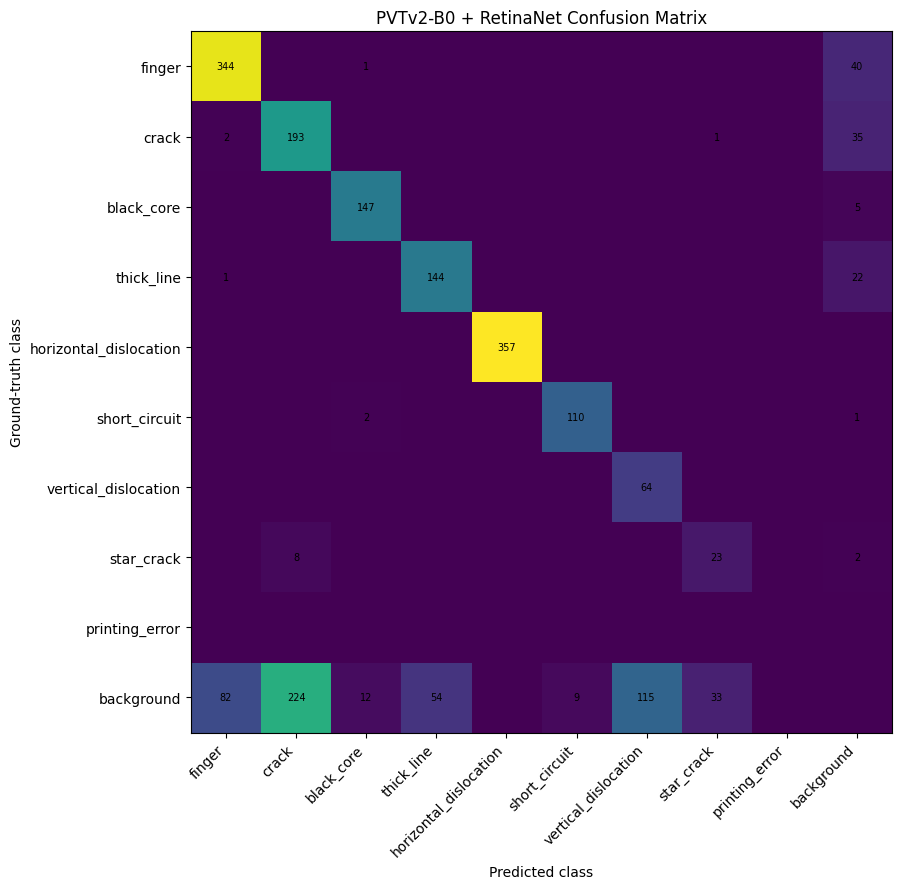

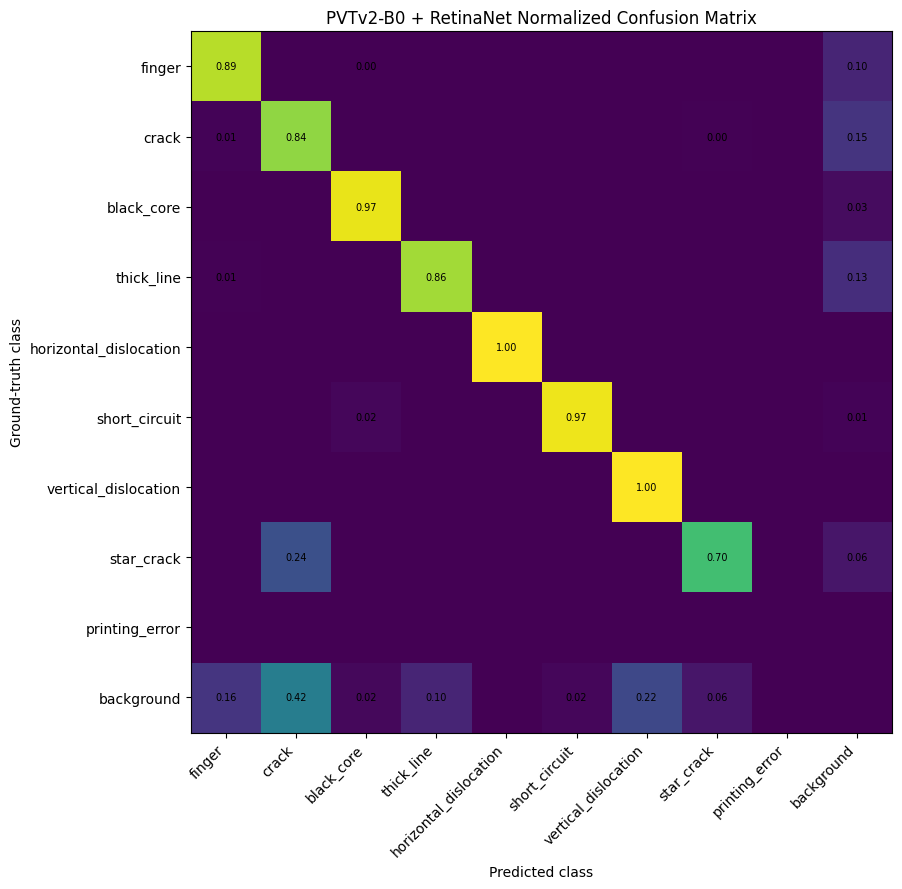

In [26]:
N = NUM_CLASSES
BG = N

confusion = np.zeros(
    (N + 1, N + 1),
    dtype=np.int64,
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    used_p = set()
    used_g = set()

    if (
        len(p_boxes)
        and len(g_boxes)
    ):
        ious = box_iou(
            p_boxes,
            g_boxes,
        )

        candidates = []

        for pi in range(
            len(p_boxes)
        ):
            for gi in range(
                len(g_boxes)
            ):
                iou = float(
                    ious[pi, gi]
                )

                if (
                    iou
                    >= MATCH_IOU_THRESHOLD
                ):
                    candidates.append(
                        (
                            iou,
                            pi,
                            gi,
                        )
                    )

        candidates.sort(
            reverse=True
        )

        for (
            iou,
            pi,
            gi,
        ) in candidates:
            if (
                pi in used_p
                or gi in used_g
            ):
                continue

            used_p.add(pi)
            used_g.add(gi)

            confusion[
                int(g_labels[gi]),
                int(p_labels[pi]),
            ] += 1

    for gi, cls_id in enumerate(
        g_labels.tolist()
    ):
        if gi not in used_g:
            confusion[
                int(cls_id),
                BG,
            ] += 1

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in used_p:
            confusion[
                BG,
                int(cls_id),
            ] += 1


labels_cm = (
    CLASS_NAMES
    + ["background"]
)

row_sums = confusion.sum(
    axis=1,
    keepdims=True,
)

normalized = np.divide(
    confusion,
    row_sums,
    out=np.zeros_like(
        confusion,
        dtype=float,
    ),
    where=row_sums != 0,
)

pd.DataFrame(
    confusion,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix.csv"
)

pd.DataFrame(
    normalized,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix_normalized.csv"
)


def plot_confusion(
    matrix,
    title,
    filename,
    fmt,
):
    fig, ax = plt.subplots(
        figsize=(11, 9)
    )

    ax.imshow(matrix)

    ax.set_xticks(
        range(len(labels_cm))
    )

    ax.set_yticks(
        range(len(labels_cm))
    )

    ax.set_xticklabels(
        labels_cm,
        rotation=45,
        ha="right",
    )

    ax.set_yticklabels(
        labels_cm
    )

    ax.set_xlabel(
        "Predicted class"
    )

    ax.set_ylabel(
        "Ground-truth class"
    )

    ax.set_title(title)

    for i in range(
        matrix.shape[0]
    ):
        for j in range(
            matrix.shape[1]
        ):
            value = matrix[i, j]

            text = (
                f"{value:.2f}"
                if fmt == "float"
                else str(int(value))
            )

            if value != 0:
                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                    fontsize=7,
                )

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_confusion(
    confusion,
    "PVTv2-B0 + RetinaNet Confusion Matrix",
    "confusion_matrix.png",
    "int",
)

plot_confusion(
    normalized,
    "PVTv2-B0 + RetinaNet Normalized Confusion Matrix",
    "confusion_matrix_normalized.png",
    "float",
)

## 23. Ground Truth vs Prediction

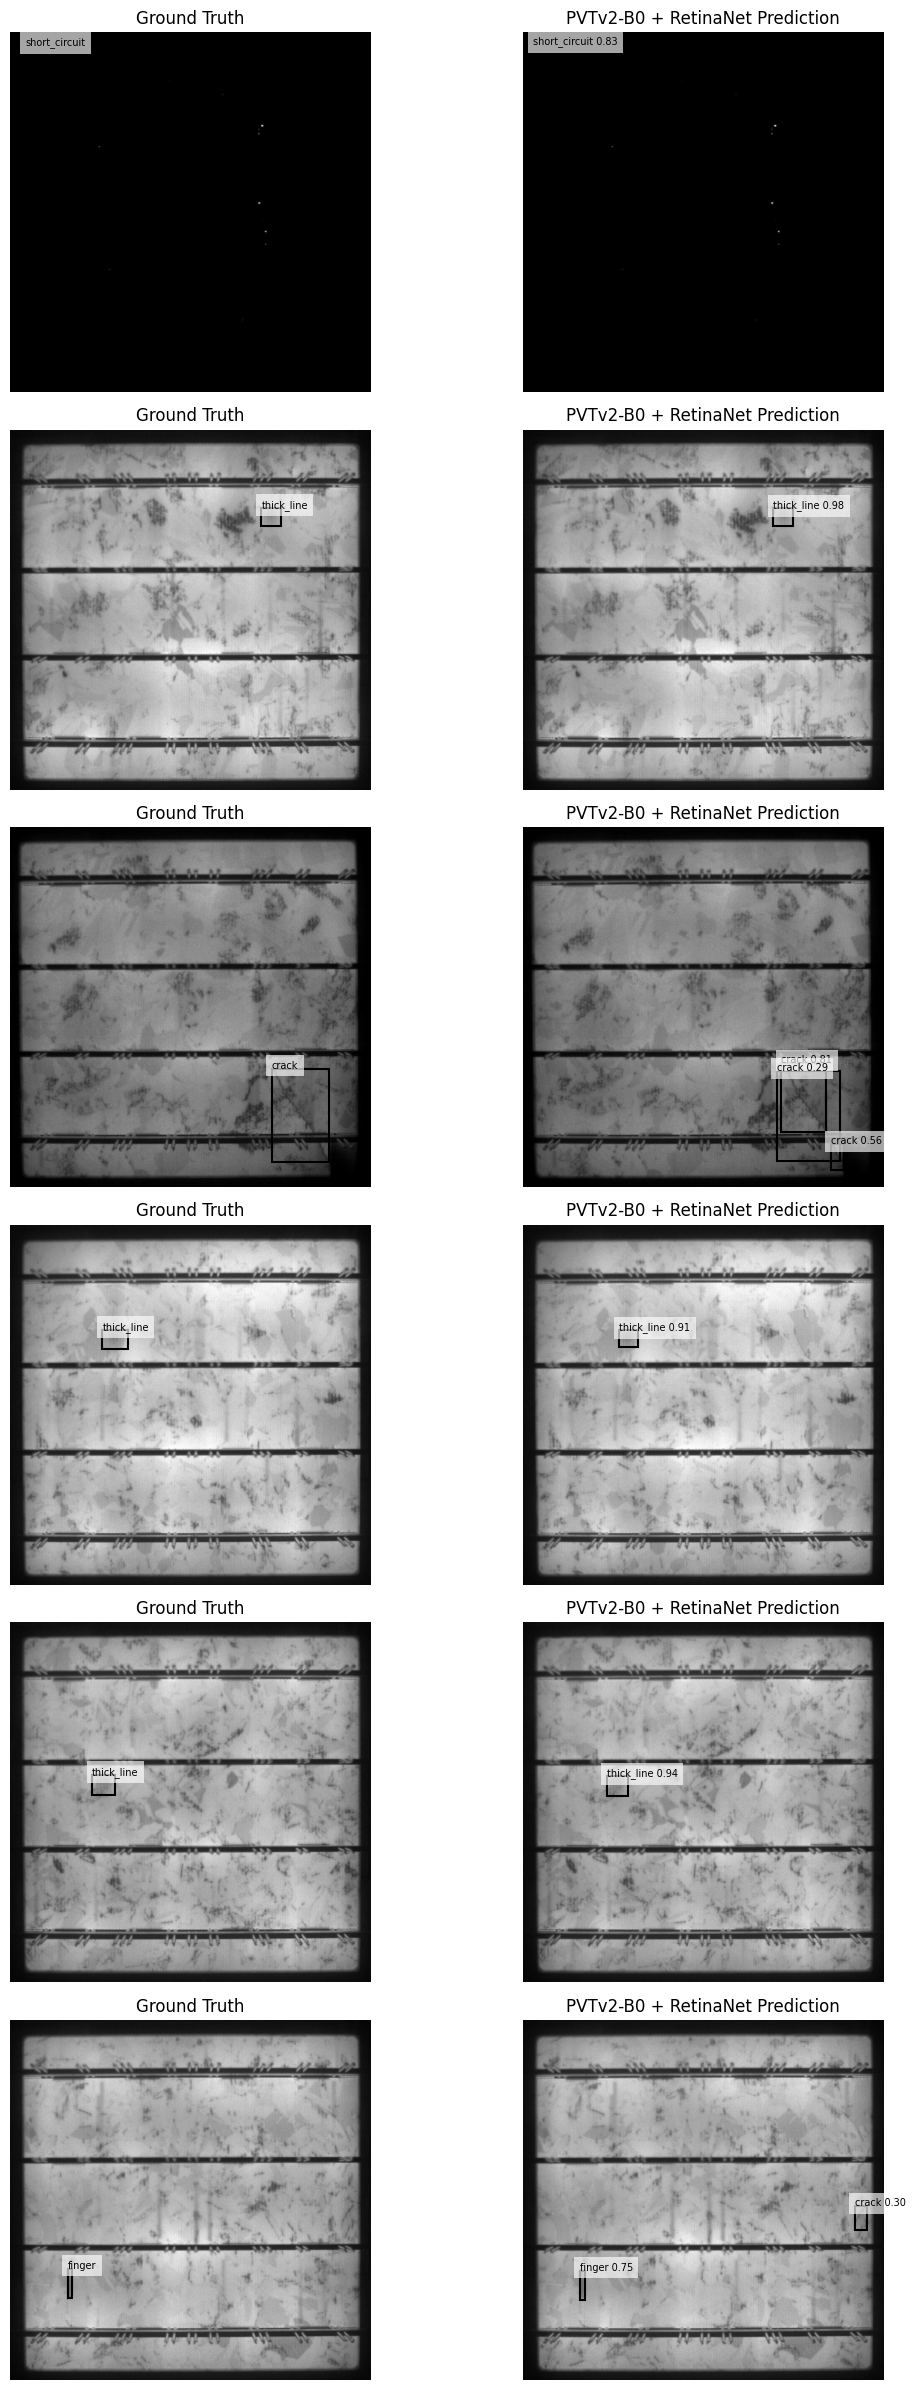

In [27]:
from matplotlib.patches import Rectangle

def show_box(
    ax,
    box,
    label,
    linewidth=1.5,
):
    x1, y1, x2, y2 = box

    rect = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=linewidth,
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(10, y1),
        label,
        fontsize=7,
        bbox=dict(
            facecolor="white",
            alpha=0.65,
            edgecolor="none",
        ),
    )


defect_indices = [
    i
    for i, target
    in enumerate(test_targets)
    if len(target["boxes"]) > 0
]

random.seed(SEED)

sample_indices = random.sample(
    defect_indices,
    min(
        6,
        len(defect_indices),
    ),
)

fig, axes = plt.subplots(
    len(sample_indices),
    2,
    figsize=(
        12,
        4 * len(sample_indices),
    ),
)

if len(sample_indices) == 1:
    axes = np.array([axes])

for row, idx in enumerate(
    sample_indices
):
    image_tensor, gt, _ = (
        test_dataset[idx]
    )

    image_np = (
        image_tensor
        .permute(1, 2, 0)
        .numpy()
        .clip(0, 1)
    )

    pred = test_predictions[idx]

    axes[row, 0].imshow(
        image_np
    )

    for box, cls_id in zip(
        gt["boxes"].numpy(),
        gt["labels"].numpy(),
    ):
        show_box(
            axes[row, 0],
            box,
            CLASS_NAMES[
                int(cls_id)
            ],
        )

    axes[row, 0].set_title(
        "Ground Truth"
    )

    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        image_np
    )

    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    for (
        box,
        cls_id,
        score,
    ) in zip(
        pred["boxes"][keep].numpy(),
        pred["labels"][keep].numpy(),
        pred["scores"][keep].numpy(),
    ):
        show_box(
            axes[row, 1],
            box,
            (
                f"{CLASS_NAMES[int(cls_id)]} "
                f"{score:.2f}"
            ),
        )

    axes[row, 1].set_title(
        "PVTv2-B0 + RetinaNet Prediction"
    )

    axes[row, 1].axis("off")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "ground_truth_vs_prediction.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 24. Model complexity

In [28]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

mamba_params = sum(
    p.numel()
    for p
    in model.backbone
    .deep_mamba
    .parameters()
)

asff_params = sum(
    p.numel()
    for p
    in model.backbone
    .asff
    .parameters()
)

model_size_mb = (
    BEST_PT.stat().st_size
    / 1024**2
    if BEST_PT.exists()
    else np.nan
)

model_info_df = pd.DataFrame([{
    "model":
        "PVTv2-B0 + BiMamba + FPN + ASFF + RetinaNet",

    "parameters":
        total_params,

    "parameters_M":
        total_params / 1e6,

    "trainable_parameters":
        trainable_params,

    "trainable_parameters_M":
        trainable_params / 1e6,

    "mamba_parameters":
        mamba_params,

    "mamba_parameters_M":
        mamba_params / 1e6,

    "asff_parameters":
        asff_params,

    "asff_parameters_M":
        asff_params / 1e6,

    "best_checkpoint_size_MB":
        model_size_mb,
}]).round(4)

model_info_df.to_csv(
    METRICS_DIR
    / "model_info.csv",
    index=False,
)

display(model_info_df)

,model,parameters,parameters_M,trainable_parameters,trainable_parameters_M,mamba_parameters,mamba_parameters_M,asff_parameters,asff_parameters_M,best_checkpoint_size_MB
0,PVTv2-B0 + BiMamba + FPN + ASFF + RetinaNet,13701378,13.7014,13701378,13.7014,438273,0.4383,1788972,1.789,52.3318


# 25. Final model summary

This summarizes the already-computed A2 test results.
It does **not** retrain or re-run the test set.

In [29]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df["epoch"].max()
)

best_checkpoint_meta = torch.load(
    BEST_PT,
    map_location="cpu",
)

best_epoch = int(
    best_checkpoint_meta.get(
        "epoch",
        history_df.loc[
            history_df[
                "val/mAP50-95"
            ].idxmax(),
            "epoch",
        ],
    )
)

early_stopped = (
    epochs_completed
    < MAX_EPOCHS
)

final_summary_df = pd.DataFrame([{
    "Model":
        "PVTv2-B0 + BiMamba + FPN + ASFF + RetinaNet",

    "Experiment":
        "A2_Aug_Mamba_ASFF",

    "Epochs Completed":
        epochs_completed,

    "Best Epoch":
        best_epoch,

    "Early Stopped":
        early_stopped,

    "Precision":
        test_precision,

    "Recall":
        test_recall,

    "F1":
        test_f1,

    "mAP@50":
        test_map50,

    "mAP@75":
        test_map75,

    "mAP@50-95":
        test_map50_95,

    "Mean Box IoU":
        mean_iou,

    "Mean Box Dice":
        mean_dice,

    "Matched Boxes":
        len(matched_ious),

    "Parameters (M)":
        total_params / 1e6,

    "Trainable Parameters (M)":
        trainable_params / 1e6,

    "Mamba Parameters (M)":
        mamba_params / 1e6,

    "ASFF Parameters (M)":
        asff_params / 1e6,

    "Model Size (MB)":
        model_size_mb,

    "Physical Batch":
        BATCH_SIZE,

    "Gradient Accumulation":
        ACCUM_STEPS,

    "Effective Batch":
        EFFECTIVE_BATCH,

    "Mean Train Time/Epoch (min)":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "Mean Val-Loss Time/Epoch (min)":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "Mean Val-mAP Time/Epoch (min)":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "Mean Total Time/Epoch (min)":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "Total Training Run Time (min)":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "Peak VRAM (GB)":
        history_df[
            "peak_vram_GB"
        ].max(),

    "Inference (ms/image)":
        inference_ms,

    "FPS":
        fps,
}]).round(4)

print("=" * 78)

print(
    "PVTv2-B0 + MAMBA + ASFF + RETINANET "
    "AUGMENTED — FINAL MODEL SUMMARY"
)

print("=" * 78)

display(final_summary_df)

print(
    "\nPER-CLASS TEST PERFORMANCE"
)

display(per_class_df)

final_summary_df.to_csv(
    METRICS_DIR
    / "final_model_summary.csv",
    index=False,
)

print("\nSaved:")

print(
    METRICS_DIR
    / "final_model_summary.csv"
)

print(
    METRICS_DIR
    / "final_per_class_summary.csv"
)


PVTv2-B0 + MAMBA + ASFF + RETINANET AUGMENTED — FINAL MODEL SUMMARY


,Model,Experiment,Epochs Completed,Best Epoch,Early Stopped,Precision,Recall,F1,mAP@50,mAP@75,...,Gradient Accumulation,Effective Batch,Mean Train Time/Epoch (min),Mean Val-Loss Time/Epoch (min),Mean Val-mAP Time/Epoch (min),Mean Total Time/Epoch (min),Total Training Run Time (min),Peak VRAM (GB),Inference (ms/image),FPS
0,PVTv2-B0 + BiMamba + FPN + ASFF + RetinaNet,A2_Aug_Mamba_ASFF,14,9,True,0.7238,0.9281,0.8133,0.9073,0.6142,...,2,16,3.4996,0.3458,0.4173,4.2627,59.6782,2.8171,28.3956,35.2168



PER-CLASS TEST PERFORMANCE


,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.8042,0.8961,0.8477,0.9097,0.4600,0.7672,0.8683
1,crack,185,231,0.4612,0.8485,0.5976,0.7339,0.4305,0.7949,0.8857
2,black_core,150,152,0.9074,0.9671,0.9363,0.9740,0.8999,0.9462,0.9724
3,thick_line,149,167,0.7273,0.8623,0.7890,0.8520,0.4423,0.7668,0.8680
4,horizontal_dislocation,119,357,1.0000,1.0000,1.0000,1.0000,0.6429,0.8374,0.9115
5,short_circuit,113,113,0.9244,0.9735,0.9483,0.9564,0.9344,0.9739,0.9868
6,vertical_dislocation,16,64,0.3575,1.0000,0.5267,0.9522,0.5781,0.8181,0.9000
7,star_crack,30,33,0.5439,0.9394,0.6889,0.8800,0.4485,0.7570,0.8617
8,printing_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved:
/content/drive/MyDrive/Study Materials /CSE465/07_PVTv2B0_Mamba_ASFF_RetinaNet_Aug/metrics/final_model_summary.csv
/content/drive/MyDrive/Study Materials /CSE465/07_PVTv2B0_Mamba_ASFF_RetinaNet_Aug/metrics/final_per_class_summary.csv


## Notes for A1 vs A2 cumulative ablation

**A1**
- PVTv2-B0 + deep bidirectional Mamba + FPN + RetinaNet
- same final PVT augmentation

**A2**
- PVTv2-B0 + deep bidirectional Mamba + FPN + ASFF + RetinaNet
- same final PVT augmentation
- initialized from A1 `best.pt`

Controlled variables:
- same prepared train/validation/test split
- same 640×640 input
- same training augmentation
- same RetinaNet head and evaluation code
- same confidence/IoU conventions
- same effective batch size
- same seed

A2-specific change:
- ASFF added after FPN for P3/P4/P5
- P6/P7 unchanged
- ASFF uses spatial softmax weighting
- ASFF residual gates start at `0.1` for training
- ASFF weight-logit kernels use small random initialization instead of all zeros
- epochs 1–3 train ASFF only at `2e-4`
- epoch 4 onward jointly fine-tunes A1 + ASFF with conservative differential LRs
- the exact A1 path (ASFF gates temporarily zero) is saved as the epoch-0 fallback

Interpretation:
- `A2 − A1` is the **additional contribution of ASFF on top of Mamba**.
- `A2 − A0` is the **combined cumulative contribution of Mamba + ASFF**.
- This is a cumulative ablation, not an isolated `PVT + ASFF` experiment.

Test evaluation is performed only after selecting the best checkpoint using
validation mAP@50–95. If ASFF never beats epoch 0, the final best checkpoint
remains the unchanged transferred A1 path.


## Final Drive checkpoint verification

Do **not disconnect Colab** until this cell confirms that `best.pt` exists in
Google Drive.

In [30]:
print("=" * 72)
print("FINAL DRIVE PERSISTENCE CHECK")
print("=" * 72)

files_to_verify = [
    BEST_PT,
    LAST_PT,
    METRICS_DIR
    / "final_model_summary.csv",
    METRICS_DIR
    / "final_per_class_summary.csv",
]

missing = []

for path in files_to_verify:
    exists = path.exists()

    if exists:
        size_mb = (
            path.stat().st_size
            / 1024**2
        )

        print(
            f"✅ {path.name:35s} "
            f"{size_mb:8.2f} MB"
        )
    else:
        print(
            f"❌ {path.name:35s} MISSING"
        )
        missing.append(
            str(path)
        )

if missing:
    raise RuntimeError(
        "Some final files are missing from Google Drive. "
        "Do NOT disconnect the runtime yet."
    )

print(
    "\n✅ All required A2 files are safely present in Google Drive."
)

FINAL DRIVE PERSISTENCE CHECK
✅ best.pt                                52.33 MB
✅ last.pt                               157.07 MB
✅ final_model_summary.csv                 0.00 MB
✅ final_per_class_summary.csv             0.00 MB

✅ All required A2 files are safely present in Google Drive.
